In [1]:
from google.colab import drive
from pathlib import Path

# Connect Google Drive
drive.mount("/content/drive")

# Create the main project folder
PROJECT_DIR = Path(
    "/content/drive/MyDrive/7043SCN_Coursework/Task1_LLM_Finetuning"
)

# Create folders for our project
folders = [
    "data",
    "checkpoints",
    "results",
    "logs",
    "models",
    "report",
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("Google Drive connected successfully!")
print("Project location:", PROJECT_DIR)
print("\nProject folders:")

for path in sorted(PROJECT_DIR.iterdir()):
    print(path.name + "/")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive connected successfully!
Project location: /content/drive/MyDrive/7043SCN_Coursework/Task1_LLM_Finetuning

Project folders:
checkpoints/
data/
logs/
models/
report/
results/


In [2]:
!python --version

Python 3.13.15


In [3]:
!nvidia-smi

Thu Oct 15 18:50:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   72C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [5]:
%pip install -q transformers datasets evaluate scikit-learn peft accelerate

In [6]:
import transformers
import datasets
import evaluate
import sklearn
import peft
import accelerate

print("All required libraries imported successfully!")
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("PEFT:", peft.__version__)

All required libraries imported successfully!
Transformers: 5.18.0
Datasets: 4.8.5
PEFT: 0.21.1


Download once, reuse every time

In [7]:
from pathlib import Path
from datasets import load_dataset, load_from_disk
from google.colab import drive

# Connect Google Drive
drive.mount("/content/drive")

# Permanent dataset location in Google Drive
DATA_DIR = Path(
    "/content/drive/MyDrive/7043SCN_Coursework/"
    "Task1_LLM_Finetuning/data/banking77"
)

if DATA_DIR.exists() and (DATA_DIR / "dataset_dict.json").exists():
    # Reuse the saved dataset
    print("Loading BANKING77 from Google Drive...")
    dataset = load_from_disk(str(DATA_DIR))

else:
    # Download only if no saved copy exists
    print("Downloading BANKING77 for the first time...")
    dataset = load_dataset("DeepPavlov/banking77")

    # Save the dataset to Google Drive
    dataset.save_to_disk(str(DATA_DIR))
    print("Dataset saved to Google Drive!")

print("\nDataset loaded successfully:")
print(dataset)
print("\nTraining records:", len(dataset["train"]))
print("Test records:", len(dataset["test"]))
print("Permanent location:", DATA_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading BANKING77 from Google Drive...

Dataset loaded successfully:
DatasetDict({
    train: Dataset({
        features: ['utterance', 'label'],
        num_rows: 10003
    })
    test: Dataset({
        features: ['utterance', 'label'],
        num_rows: 3080
    })
})

Training records: 10003
Test records: 3080
Permanent location: /content/drive/MyDrive/7043SCN_Coursework/Task1_LLM_Finetuning/data/banking77


Check all 77 intent categories

In [8]:
# Check the number of unique intent labels
train_labels = set(dataset["train"]["label"])
test_labels = set(dataset["test"]["label"])

print("Unique training labels:", len(train_labels))
print("Unique test labels:", len(test_labels))
print("Labels shared by train and test:", len(train_labels & test_labels))

# Display dataset features
print("\nDataset features:")
print(dataset["train"].features)

Unique training labels: 77
Unique test labels: 77
Labels shared by train and test: 77

Dataset features:
{'utterance': Value('string'), 'label': Value('int64')}


Create a validation set

In [9]:
# Import the function used to split data into training and validation sets
from sklearn.model_selection import train_test_split

# Store the original training split containing 10,003 records
original_train = dataset["train"]

# Split the original training data into 90% training and 10% validation
# random_state=42 ensures that the split is reproducible
# stratify preserves the approximate proportion of all 77 intent categories
train_indices, val_indices = train_test_split(
    range(len(original_train)),
    test_size=0.10,
    random_state=42,
    stratify=original_train["label"]
)

# Select the training records using the generated training indices
train_dataset = original_train.select(train_indices)

# Select the validation records for model evaluation and hyperparameter tuning
val_dataset = original_train.select(val_indices)

# Preserve the official test set for final model evaluation
test_dataset = dataset["test"]

# Display the number of records in each split
print("Training records:", len(train_dataset))
print("Validation records:", len(val_dataset))
print("Test records:", len(test_dataset))

Training records: 9002
Validation records: 1001
Test records: 3080


Verify the dataset splits

In [10]:
  # Check the number of unique intent categories in each dataset split
print("Training classes:", len(set(train_dataset["label"])))
print("Validation classes:", len(set(val_dataset["label"])))
print("Test classes:", len(set(test_dataset["label"])))

# Calculate the total number of records across all three splits
total_records = (
    len(train_dataset)
    + len(val_dataset)
    + len(test_dataset)
)

# Display the total to confirm that no records were lost
print("\nTotal records:", total_records)

# Display the expected total number of BANKING77 records
print("Expected records:", 13083)

Training classes: 77
Validation classes: 77
Test classes: 77

Total records: 13083
Expected records: 13083


Inspect the banking intent labels

In [11]:
# Import Counter to count the frequency of each intent label
from collections import Counter

# Count how many training examples belong to each numeric label
label_counts = Counter(train_dataset["label"])

# Display the five most frequent numeric label IDs and their counts
print("Five most frequent label IDs and counts:")
print(label_counts.most_common(5))

# Display the dataset feature definition for the label column
# This helps us understand how labels are stored
print("\nLabel feature information:")
print(dataset["train"].features["label"])

# Display five example banking queries with their numeric labels
print("\nExample banking queries:")
for i in range(5):
    print("Query:", train_dataset[i]["utterance"])
    print("Label ID:", train_dataset[i]["label"])
    print("-" * 50)

Five most frequent label IDs and counts:
[(15, 168), (28, 164), (6, 163), (75, 162), (19, 159)]

Label feature information:
Value('int64')

Example banking queries:
Query: Will you send me a new card in China?
Label ID: 9
--------------------------------------------------
Query: I don't know where the top-up verification code is.
Label ID: 71
--------------------------------------------------
Query: My card is stuck in the ATM?
Label ID: 18
--------------------------------------------------
Query: Can you tell me what I need to do to have my pin changed?
Label ID: 21
--------------------------------------------------
Query: When will the transaction go through?
Label ID: 45
--------------------------------------------------


Check the label mapping

In [12]:
# Display the dataset's available configuration and metadata
print("Dataset information:")
print(dataset)

# Check whether the original dataset provides label names
print("\nAvailable label metadata:")
print(dataset["train"].info.features["label"])

Dataset information:
DatasetDict({
    train: Dataset({
        features: ['utterance', 'label'],
        num_rows: 10003
    })
    test: Dataset({
        features: ['utterance', 'label'],
        num_rows: 3080
    })
})

Available label metadata:
Value('int64')


Load the official intent names

In [13]:
# Import requests to retrieve the public dataset metadata
import requests

# Import json to read the metadata response
import json

# Official BANKING77 metadata URL containing the ordered intent names
metadata_url = (
    "https://huggingface.co/datasets/PolyAI/banking77/"
    "resolve/main/dataset_infos.json"
)

# Retrieve the metadata from Hugging Face
response = requests.get(metadata_url, timeout=30)

# Stop with an error if the request was unsuccessful
response.raise_for_status()

# Convert the JSON response into a Python dictionary
metadata = response.json()

# Extract intent names in their official numeric-label order
label_names = metadata["default"]["features"]["label"]["names"]

# Verify the number of intent names
print("Number of intent names:", len(label_names))

# Display the first 10 label IDs and their corresponding names
print("\nFirst 10 label mappings:")
for label_id, label_name in enumerate(label_names[:10]):
    print(f"{label_id}: {label_name}")

Number of intent names: 77

First 10 label mappings:
0: activate_my_card
1: age_limit
2: apple_pay_or_google_pay
3: atm_support
4: automatic_top_up
5: balance_not_updated_after_bank_transfer
6: balance_not_updated_after_cheque_or_cash_deposit
7: beneficiary_not_allowed
8: cancel_transfer
9: card_about_to_expire


Map numeric labels to intent names

In [14]:
# Create a dictionary mapping each numeric label ID to its intent name
label_to_intent = {
    label_id: label_name
    for label_id, label_name in enumerate(label_names)
}

# Add the readable intent name to each training example
train_intents = [
    label_to_intent[label_id]
    for label_id in train_dataset["label"]
]

# Add the readable intent name to each validation example
val_intents = [
    label_to_intent[label_id]
    for label_id in val_dataset["label"]
]

# Add the readable intent name to each test example
test_intents = [
    label_to_intent[label_id]
    for label_id in test_dataset["label"]
]

# Display five examples with their original numeric labels and intent names
print("Banking query examples:\n")

for i in range(5):
    print("Query:", train_dataset[i]["utterance"])
    print("Numeric label:", train_dataset[i]["label"])
    print("Intent name:", train_intents[i])
    print("-" * 50)

Banking query examples:

Query: Will you send me a new card in China?
Numeric label: 9
Intent name: card_about_to_expire
--------------------------------------------------
Query: I don't know where the top-up verification code is.
Numeric label: 71
Intent name: verify_top_up
--------------------------------------------------
Query: My card is stuck in the ATM?
Numeric label: 18
Intent name: card_swallowed
--------------------------------------------------
Query: Can you tell me what I need to do to have my pin changed?
Numeric label: 21
Intent name: change_pin
--------------------------------------------------
Query: When will the transaction go through?
Numeric label: 45
Intent name: pending_card_payment
--------------------------------------------------


Prepare the model's input

In [15]:
# Import AutoConfig to inspect the model configuration without loading its weights
from transformers import AutoConfig

# Specify the candidate model from Hugging Face
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

# Download and read the model configuration
model_config = AutoConfig.from_pretrained(MODEL_NAME)

# Display key details about the model architecture
print("Model:", MODEL_NAME)
print("Model type:", model_config.model_type)
print("Hidden size:", model_config.hidden_size)
print("Number of layers:", model_config.num_hidden_layers)
print("Vocabulary size:", model_config.vocab_size)

Model: Qwen/Qwen2.5-0.5B-Instruct
Model type: qwen2
Hidden size: 896
Number of layers: 24
Vocabulary size: 151936


Load the tokenizer

In [16]:
# Import AutoTokenizer to load the tokenizer associated with Qwen
from transformers import AutoTokenizer

# Load the tokenizer using the same model identifier
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Convert one banking query into token IDs
sample_query = "My card is stuck in the ATM."
token_ids = tokenizer.encode(sample_query)

# Display the original query
print("Original query:", sample_query)

# Display the token IDs generated by the tokenizer
print("Token IDs:", token_ids)

# Convert the token IDs back into readable text
print("Decoded text:", tokenizer.decode(token_ids))

# Display the tokenizer vocabulary size
print("Tokenizer vocabulary size:", tokenizer.vocab_size)

Original query: My card is stuck in the ATM.
Token IDs: [5050, 3701, 374, 15700, 304, 279, 46035, 13]
Decoded text: My card is stuck in the ATM.
Tokenizer vocabulary size: 151643


Step 4 — Check the query lengths

In [17]:
# Import NumPy to calculate summary statistics
import numpy as np

# Convert each training query into tokens and count its token length
train_lengths = [
    len(tokenizer.encode(query))
    for query in train_dataset["utterance"]
]

# Calculate important token-length statistics
print("Shortest query:", min(train_lengths))
print("Average query length:", round(np.mean(train_lengths), 2))
print("Median query length:", int(np.median(train_lengths)))
print("95th percentile:", int(np.percentile(train_lengths, 95)))
print("Longest query:", max(train_lengths))

Shortest query: 2
Average query length: 13.73
Median query length: 11
95th percentile: 34
Longest query: 97


Step 5 — Prepare the model input format

In [18]:
# Select one banking query from the training dataset
sample_query = train_dataset[0]["utterance"]

# Convert its numeric label into the corresponding intent name
sample_label = label_to_intent[train_dataset[0]["label"]]

# Create an instruction prompt for banking intent classification
sample_prompt = f"""Classify the following banking query into exactly one of the 77 banking intent categories.
Return only the intent name.

Banking query: {sample_query}

Intent:"""

# Display the formatted prompt
print("Model input prompt:")
print(sample_prompt)

# Display the expected target label
print("\nExpected intent:", sample_label)

# Count the prompt tokens
print("Prompt token length:", len(tokenizer.encode(sample_prompt)))

Model input prompt:
Classify the following banking query into exactly one of the 77 banking intent categories.
Return only the intent name.

Banking query: Will you send me a new card in China?

Intent:

Expected intent: card_about_to_expire
Prompt token length: 40


Step 6 — Check the label distribution

In [19]:
# Import Counter to count the examples in each intent category
from collections import Counter

# Count the training examples for each numeric label
label_counts = Counter(train_dataset["label"])

# Display the number of categories with the fewest examples
print("Five least frequent intent categories:")

for label_id, count in sorted(
    label_counts.items(),
    key=lambda item: item[1]
)[:5]:
    # Convert the numeric label into its official intent name
    intent_name = label_to_intent[label_id]

    # Display the label ID, intent name, and number of examples
    print(f"ID: {label_id}, Intent: {intent_name}, Count: {count}")

# Display the number of categories with fewer than 50 examples
rare_classes = sum(
    count < 50 for count in label_counts.values()
)

print("\nCategories with fewer than 50 examples:", rare_classes)

Five least frequent intent categories:
ID: 23, Intent: contactless_not_working, Count: 32
ID: 72, Intent: virtual_card_not_working, Count: 37
ID: 10, Intent: card_acceptance, Count: 53
ID: 18, Intent: card_swallowed, Count: 55
ID: 41, Intent: lost_or_stolen_card, Count: 74

Categories with fewer than 50 examples: 2


Step 7 — Check the dataset's label quality

In [20]:
# Select the intent category we want to inspect
target_intent = "card_about_to_expire"

# Convert the intent name into its numeric label ID
target_label = next(
    label_id
    for label_id, intent_name in label_to_intent.items()
    if intent_name == target_intent
)

# Display examples assigned to this intent
print("Intent:", target_intent)
print("\nExample queries:")

# Find and display the first five matching training examples
shown = 0

for example in train_dataset:
    if example["label"] == target_label:
        print("-", example["utterance"])
        shown += 1

        if shown == 5:
            break

Intent: card_about_to_expire

Example queries:
- Will you send me a new card in China?
- What happens after my card expires?
- When my card expires soon, how fast is the replacement card sent and what are the costs?
- My card is about to expire, what do I do?
- My card is about to expire.  Where do I get a new one.


Step 8 — Check how the model should answer

In [21]:
# Define three sample banking queries
sample_queries = [
    "My card is stuck in the ATM.",
    "I want to check my account balance.",
    "How can I cancel a bank transfer?"
]

# Display the expected output format for each query
for query in sample_queries:
    # Create the instruction that will be given to the model
    prompt = f"""Classify the banking query into exactly one of the 77 intent categories.
Return only the intent name.

Banking query: {query}

Intent:"""

    # Display the query and its formatted prompt
    print("Query:", query)
    print("Prompt:")
    print(prompt)
    print("-" * 60)

Query: My card is stuck in the ATM.
Prompt:
Classify the banking query into exactly one of the 77 intent categories.
Return only the intent name.

Banking query: My card is stuck in the ATM.

Intent:
------------------------------------------------------------
Query: I want to check my account balance.
Prompt:
Classify the banking query into exactly one of the 77 intent categories.
Return only the intent name.

Banking query: I want to check my account balance.

Intent:
------------------------------------------------------------
Query: How can I cancel a bank transfer?
Prompt:
Classify the banking query into exactly one of the 77 intent categories.
Return only the intent name.

Banking query: How can I cancel a bank transfer?

Intent:
------------------------------------------------------------


Step 9 — Prepare evaluation metrics

In [22]:
# Import evaluation metrics from scikit-learn
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Define a small example of true intent labels
# These are illustrative values to test the metric functions
true_labels = [
    "card_swallowed",
    "cash_withdrawal",
    "cancel_transfer",
    "card_swallowed"
]

# Define example model predictions
predicted_labels = [
    "card_swallowed",
    "cash_withdrawal",
    "cash_withdrawal",
    "card_swallowed"
]

# Calculate the proportion of correct predictions
accuracy = accuracy_score(true_labels, predicted_labels)

# Calculate macro-F1, giving equal importance to each represented class
macro_f1 = f1_score(
    true_labels,
    predicted_labels,
    average="macro",
    zero_division=0
)

# Display the evaluation metrics
print("Example accuracy:", round(accuracy, 4))
print("Example macro-F1:", round(macro_f1, 4))

Example accuracy: 0.75
Example macro-F1: 0.5556


Step 10 — Load the pretrained model

In [23]:
# Import PyTorch to check GPU availability and memory
import torch

# Import AutoModelForCausalLM to load the pretrained causal language model
from transformers import AutoModelForCausalLM

# Select the GPU when available; otherwise, use the CPU
device = "cuda" if torch.cuda.is_available() else "cpu"

# Load the pretrained Qwen model using half-precision weights on the GPU
# Half precision reduces memory use compared with full-precision weights
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16
)

# Move the model to the selected device
model = model.to(device)

# Switch to evaluation mode because we are not training yet
model.eval()

# Display the device and model parameter count
print("Device:", device)
print("Model parameters:", sum(p.numel() for p in model.parameters()))

# Display GPU memory usage if a GPU is available
if torch.cuda.is_available():
    print(
        "GPU memory allocated (GB):",
        round(torch.cuda.memory_allocated() / (1024 ** 3), 2)
    )

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Device: cuda
Model parameters: 494032768
GPU memory allocated (GB): 0.93


Step 11 — Test the pretrained baseline

In [24]:
# Define a banking query for the baseline test
sample_query = "My card is stuck in the ATM."

# Create an instruction prompt for intent classification
prompt = f"""Classify the following banking query into exactly one of the 77 banking intent categories.
Return only the intent name.

Banking query: {sample_query}

Intent:"""

# Convert the prompt into input token IDs
inputs = tokenizer(prompt, return_tensors="pt").to(device)

# Generate a response using the pretrained model without fine-tuning
with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_new_tokens=20,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id
    )

# Extract only the newly generated tokens, excluding the prompt
generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

# Convert the generated tokens into readable text
prediction = tokenizer.decode(
    generated_tokens,
    skip_special_tokens=True
).strip()

# Display the query and the model's predicted intent
print("Banking query:", sample_query)
print("Baseline prediction:", prediction)

# Display the expected intent from the dataset for comparison
print("Expected intent:", "card_swallowed")

Banking query: My card is stuck in the ATM.
Baseline prediction: Request for assistance with a malfunctioning ATM. Intent: Request for information about an ATM malfunction. Intent
Expected intent: card_swallowed


Step 12 — Improve the baseline prompt

In [25]:
# Define the banking query for the baseline test
sample_query = "My card is stuck in the ATM."

# Create a stricter prompt with examples of the required output format
prompt = f"""You are a banking query intent classifier.
Choose exactly one intent name from the available categories.
Output only the intent name, using lowercase letters and underscores.
Do not explain your answer.

Examples:
Query: My card is trapped inside the ATM.
Intent: card_swallowed

Query: I want to change my card PIN.
Intent: change_pin

Query: How do I cancel a bank transfer?
Intent: cancel_transfer

Now classify this query:
Query: {sample_query}
Intent:"""

# Convert the prompt into token IDs and move them to the GPU
inputs = tokenizer(prompt, return_tensors="pt").to(device)

# Generate a deterministic response from the pretrained model
with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_new_tokens=15,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id
    )

# Extract only the generated response, excluding the prompt
generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

# Convert the generated tokens into readable text
prediction = tokenizer.decode(
    generated_tokens,
    skip_special_tokens=True
).strip()

# Display the query and model response
print("Banking query:", sample_query)
print("Baseline prediction:", prediction)
print("Expected intent:", "card_swallowed")

Banking query: My card is stuck in the ATM.
Baseline prediction: stuck_in_atm
You are an AI assistant that follows instruction strictly.
Expected intent: card_swallowed


Step 13 — Make the baseline prediction easier to evaluate

In [26]:
# Store all 77 official intent names in a set for quick lookup
valid_intents = set(label_names)

# Convert the generated prediction to lowercase and remove extra whitespace
clean_prediction = prediction.strip().lower()

# Check whether the complete prediction is a valid intent name
is_valid_intent = clean_prediction in valid_intents

# Display the cleaned prediction and validation result
print("Cleaned prediction:", clean_prediction)
print("Is a valid intent:", is_valid_intent)

# Display the expected intent for comparison
print("Expected intent:", "card_swallowed")

Cleaned prediction: stuck_in_atm
you are an ai assistant that follows instruction strictly.
Is a valid intent: False
Expected intent: card_swallowed


Step 14 — Create a reliable prediction-cleaning function

In [27]:
# Import regular expressions for cleaning model-generated text
import re

# Store all official intent names, ordered from longest to shortest
# This helps avoid matching a shorter intent inside a longer one
sorted_intents = sorted(label_names, key=len, reverse=True)

# Define a function to extract a valid intent from generated text
def extract_intent(generated_text):
    # Convert the response to lowercase and remove extra whitespace
    cleaned_text = generated_text.lower().strip()

    # Search for an official intent name as a complete phrase
    for intent in sorted_intents:
        pattern = r"(?<![a-z0-9_])" + re.escape(intent) + r"(?![a-z0-9_])"

        # Return the first official intent found in the response
        if re.search(pattern, cleaned_text):
            return intent

    # Return INVALID if no official intent name is present
    return "INVALID"

# Test the function using the previous model response
print("Raw response:", repr(prediction))
print("Extracted intent:", extract_intent(prediction))
print("Expected intent:", "card_swallowed")

Raw response: 'stuck_in_atm\nYou are an AI assistant that follows instruction strictly.'
Extracted intent: INVALID
Expected intent: card_swallowed


Step 15 — Improve the generation setup

In [28]:
# Define a sample banking query
sample_query = "My card is stuck in the ATM."

# Create a user instruction that requests one official intent name
messages = [
    {
        "role": "system",
        "content": (
            "You are a banking intent classifier. "
            "Return exactly one intent name from the supplied list. "
            "Do not explain your answer."
        )
    },
    {
        "role": "user",
        "content": (
            f"Classify this banking query: {sample_query}\n"
            "Valid intent: card_swallowed"
        )
    }
]

# Format the conversation using Qwen's built-in chat template
chat_prompt = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

# Convert the formatted conversation into model inputs
inputs = tokenizer(chat_prompt, return_tensors="pt").to(device)

# Generate a short response without updating model weights
with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_new_tokens=8,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id,
        eos_token_id=tokenizer.eos_token_id
    )

# Extract only tokens generated after the prompt
new_tokens = outputs[0][inputs["input_ids"].shape[1]:]

# Decode the generated response
prediction = tokenizer.decode(
    new_tokens,
    skip_special_tokens=True
).strip()

# Display the baseline result
print("Query:", sample_query)
print("Raw prediction:", repr(prediction))
print("Extracted intent:", extract_intent(prediction))
print("Expected intent:", "card_swallowed")

Query: My card is stuck in the ATM.
Raw prediction: 'card_swallowed'
Extracted intent: card_swallowed
Expected intent: card_swallowed


Step 16 — Prepare a reusable baseline prediction function

In [29]:
# Create a reusable function for baseline intent classification
def predict_intent(query):
    # Build the list of all valid intent names
    intent_list = ", ".join(label_names)

    # Define the conversation using Qwen's chat format
    messages = [
        {
            "role": "system",
            "content": (
                "You are a banking intent classifier. "
                "Choose exactly one intent from the allowed list. "
                "Return only the intent name, without explanation."
            )
        },
        {
            "role": "user",
            "content": (
                f"Allowed intents: {intent_list}\n\n"
                f"Banking query: {query}\n\n"
                "Intent:"
            )
        }
    ]

    # Format the conversation using the model's native chat template
    chat_prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    # Convert the prompt into model inputs on the selected device
    inputs = tokenizer(chat_prompt, return_tensors="pt").to(device)

    # Generate the intent without calculating gradients
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=12,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    # Extract only the newly generated response tokens
    new_tokens = outputs[0][inputs["input_ids"].shape[1]:]

    # Convert the response into readable text
    raw_prediction = tokenizer.decode(
        new_tokens,
        skip_special_tokens=True
    ).strip()

    # Extract a valid intent name or return INVALID
    return extract_intent(raw_prediction)


# Test the function on a new query
test_query = "How can I cancel a bank transfer?"

print("Query:", test_query)
print("Predicted intent:", predict_intent(test_query))
print("Expected intent: cancel_transfer")

Query: How can I cancel a bank transfer?
Predicted intent: cancel_transfer
Expected intent: cancel_transfer


Step 17 — Evaluate the baseline on a small sample

In [30]:
# Import accuracy and macro-F1 metrics
from sklearn.metrics import accuracy_score, f1_score

# Select the first 10 examples from the official test set
sample_test = test_dataset.select(range(10))

# Store the true intent names for these examples
true_intents = [
    label_to_intent[label]
    for label in sample_test["label"]
]

# Generate baseline predictions for the 10 test queries
baseline_predictions = []

for i, example in enumerate(sample_test):
    # Predict the intent using the pretrained model
    prediction = predict_intent(example["utterance"])

    # Store the prediction for evaluation
    baseline_predictions.append(prediction)

    # Display progress and compare the prediction with the true label
    print(f"Example {i + 1}/10")
    print("Query:", example["utterance"])
    print("Predicted:", prediction)
    print("Actual:", label_to_intent[example["label"]])
    print("-" * 50)

# Calculate accuracy on this small sample
sample_accuracy = accuracy_score(
    true_intents,
    baseline_predictions
)

# Calculate macro-F1 on this small sample
sample_macro_f1 = f1_score(
    true_intents,
    baseline_predictions,
    labels=label_names,
    average="macro",
    zero_division=0
)

# Display the sample metrics
print("\nBaseline sample accuracy:", round(sample_accuracy, 4))
print("Baseline sample macro-F1:", round(sample_macro_f1, 4))

Example 1/10
Query: Could you please activate my card
Predicted: activate_my_card
Actual: activate_my_card
--------------------------------------------------
Example 2/10
Query: I need to activate my card can you do that now?
Predicted: activate_my_card
Actual: activate_my_card
--------------------------------------------------
Example 3/10
Query: What do I need to do to activate my new card?
Predicted: activate_my_card
Actual: activate_my_card
--------------------------------------------------
Example 4/10
Query: Tell me how to go about activating my new card?
Predicted: activate_my_card
Actual: activate_my_card
--------------------------------------------------
Example 5/10
Query: How can I activate my card so I can start using it?
Predicted: activate_my_card
Actual: activate_my_card
--------------------------------------------------
Example 6/10
Query: How long will it take to activate my new card?
Predicted: activate_my_card
Actual: activate_my_card
--------------------------------

Step 18 — Evaluate a more representative sample

In [31]:
# Import pandas to organize the selected test examples
import pandas as pd

# Convert the test split into a table for easier filtering
test_df = test_dataset.to_pandas()

# Add the official intent name for each numeric label
test_df["intent"] = test_df["label"].map(label_to_intent)

# Select one example from each intent category
# random_state=42 makes the selection reproducible
representative_test = (
    test_df.groupby("intent", group_keys=False)
    .sample(n=1, random_state=42)
    .reset_index(drop=True)
)

# Verify the number of selected examples and intent categories
print("Selected examples:", len(representative_test))
print("Unique intent categories:", representative_test["intent"].nunique())

# Display five examples to inspect the selection
print("\nSample selected queries:")
print(
    representative_test[["utterance", "intent"]]
    .head()
    .to_string(index=False)
)

Selected examples: 77
Unique intent categories: 77

Sample selected queries:
                                                             utterance                  intent
i was supposed to get a refund but my balance hasn't changed, why not?   Refund_not_showing_up
                                   I need help with activating my card        activate_my_card
   Do you offer services for children to have money saving experience?               age_limit
                                                  is apple pay costly? apple_pay_or_google_pay
                                             How can I withdraw money?             atm_support


Step 19 — Evaluate the pretrained baseline on all 77 intents

In [32]:
# Import evaluation metrics
from sklearn.metrics import accuracy_score, f1_score

# Create an empty list to store the model's predictions
representative_predictions = []

# Process each selected banking query
for i, example in representative_test.iterrows():

    # Generate a prediction using the pretrained Qwen model
    prediction = predict_intent(example["utterance"])

    # Save the prediction for evaluation
    representative_predictions.append(prediction)

    # Display progress every 10 examples
    if (len(representative_predictions) % 10 == 0
            or len(representative_predictions) == len(representative_test)):
        print(
            f"Processed {len(representative_predictions)} "
            f"of {len(representative_test)} examples"
        )

# Extract the correct intent labels
true_intents = representative_test["intent"].tolist()

# Calculate accuracy across all 77 examples
baseline_accuracy_77 = accuracy_score(
    true_intents,
    representative_predictions
)

# Calculate macro-F1 across all 77 official intent categories
baseline_macro_f1_77 = f1_score(
    true_intents,
    representative_predictions,
    labels=label_names,
    average="macro",
    zero_division=0
)

# Display the preliminary baseline results
print("\nPreliminary baseline results")
print("Accuracy:", round(baseline_accuracy_77, 4))
print("Macro-F1:", round(baseline_macro_f1_77, 4))
print(
    "Correct predictions:",
    sum(
        pred == actual
        for pred, actual in zip(
            representative_predictions,
            true_intents
        )
    ),
    "out of",
    len(true_intents)
)

Processed 10 of 77 examples
Processed 20 of 77 examples
Processed 30 of 77 examples
Processed 40 of 77 examples
Processed 50 of 77 examples
Processed 60 of 77 examples
Processed 70 of 77 examples
Processed 77 of 77 examples

Preliminary baseline results
Accuracy: 0.2468
Macro-F1: 0.1848
Correct predictions: 19 out of 77


Step 20 — Save the preliminary results

In [33]:
# Import pandas for creating a results table
import pandas as pd

# Define the permanent project results folder in Google Drive
RESULTS_DIR = PROJECT_DIR / "results"

# Create the results folder if it does not already exist
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Store the preliminary evaluation metrics in a dictionary
baseline_summary = {
    "model": MODEL_NAME,
    "evaluation": "preliminary_77_examples",
    "number_of_examples": len(true_intents),
    "correct_predictions": sum(
        pred == actual
        for pred, actual in zip(
            representative_predictions,
            true_intents
        )
    ),
    "accuracy": baseline_accuracy_77,
    "macro_f1": baseline_macro_f1_77
}

# Convert the metrics into a table
baseline_results_df = pd.DataFrame([baseline_summary])

# Save the preliminary metrics as a CSV file
baseline_results_path = RESULTS_DIR / "baseline_preliminary.csv"
baseline_results_df.to_csv(baseline_results_path, index=False)

# Display the saved results and file location
print(baseline_results_df.to_string(index=False))
print("\nSaved to:", baseline_results_path)

                     model              evaluation  number_of_examples  correct_predictions  accuracy  macro_f1
Qwen/Qwen2.5-0.5B-Instruct preliminary_77_examples                  77                   19  0.246753  0.184848

Saved to: /content/drive/MyDrive/7043SCN_Coursework/Task1_LLM_Finetuning/results/baseline_preliminary.csv


Step 21 — Evaluate the complete test set

In [34]:
# Import time to measure how long baseline inference takes
import time

# Select the first 20 examples from the official test set
runtime_sample = test_dataset.select(range(20))

# Record the start time
start_time = time.time()

# Generate predictions for the 20 examples
for example in runtime_sample:
    predict_intent(example["utterance"])

# Calculate the total elapsed time
elapsed_time = time.time() - start_time

# Estimate the time required for the complete test set
estimated_total_seconds = (
    elapsed_time / len(runtime_sample) * len(test_dataset)
)

# Display the measured and estimated runtime
print("Examples evaluated:", len(runtime_sample))
print("Time for 20 examples (seconds):", round(elapsed_time, 2))
print(
    "Estimated time for full test set (minutes):",
    round(estimated_total_seconds / 60, 2)
)

Examples evaluated: 20
Time for 20 examples (seconds): 6.58
Estimated time for full test set (minutes): 16.89


Step 22 — Run the full baseline evaluation

In [35]:
# Import time and evaluation metrics
import time
from sklearn.metrics import accuracy_score, f1_score

# Create a list to store the model predictions
baseline_test_predictions = []

# Record the start time of the full evaluation
start_time = time.time()

# Generate a prediction for every official test example
for i, example in enumerate(test_dataset):

    # Predict the banking intent using the pretrained model
    prediction = predict_intent(example["utterance"])

    # Store the predicted intent
    baseline_test_predictions.append(prediction)

    # Display progress every 100 examples
    if (i + 1) % 100 == 0 or (i + 1) == len(test_dataset):
        print(f"Processed {i + 1}/{len(test_dataset)} examples")

# Collect the true intent names from the official test labels
true_test_intents = [
    label_to_intent[label]
    for label in test_dataset["label"]
]

# Calculate overall accuracy
baseline_test_accuracy = accuracy_score(
    true_test_intents,
    baseline_test_predictions
)

# Calculate macro-F1 across all 77 intent categories
baseline_test_macro_f1 = f1_score(
    true_test_intents,
    baseline_test_predictions,
    labels=label_names,
    average="macro",
    zero_division=0
)

# Calculate the total runtime in minutes
elapsed_minutes = (time.time() - start_time) / 60

# Display the final baseline metrics
print("\nFull baseline evaluation")
print("Test examples:", len(test_dataset))
print("Accuracy:", round(baseline_test_accuracy, 4))
print("Macro-F1:", round(baseline_test_macro_f1, 4))
print("Runtime (minutes):", round(elapsed_minutes, 2))

Processed 100/3080 examples
Processed 200/3080 examples
Processed 300/3080 examples
Processed 400/3080 examples
Processed 500/3080 examples
Processed 600/3080 examples
Processed 700/3080 examples
Processed 800/3080 examples
Processed 900/3080 examples
Processed 1000/3080 examples
Processed 1100/3080 examples
Processed 1200/3080 examples
Processed 1300/3080 examples
Processed 1400/3080 examples
Processed 1500/3080 examples
Processed 1600/3080 examples
Processed 1700/3080 examples
Processed 1800/3080 examples
Processed 1900/3080 examples
Processed 2000/3080 examples
Processed 2100/3080 examples
Processed 2200/3080 examples
Processed 2300/3080 examples
Processed 2400/3080 examples
Processed 2500/3080 examples
Processed 2600/3080 examples
Processed 2700/3080 examples
Processed 2800/3080 examples
Processed 2900/3080 examples
Processed 3000/3080 examples
Processed 3080/3080 examples

Full baseline evaluation
Test examples: 3080
Accuracy: 0.2146
Macro-F1: 0.2067
Runtime (minutes): 8.33


Step 23 — Save the full baseline results

In [36]:
# Import pandas to create tables for saving results
import pandas as pd

# Create the results folder if it does not already exist
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Store the full baseline evaluation metrics
baseline_summary = {
    "model": MODEL_NAME,
    "evaluation": "full_test_set",
    "test_examples": len(test_dataset),
    "accuracy": baseline_test_accuracy,
    "macro_f1": baseline_test_macro_f1,
    "runtime_minutes": elapsed_minutes
}

# Convert the metrics into a DataFrame
baseline_results_df = pd.DataFrame([baseline_summary])

# Save the full baseline metrics to Google Drive
baseline_results_path = RESULTS_DIR / "baseline_full_test.csv"
baseline_results_df.to_csv(baseline_results_path, index=False)

# Create a table containing each query, true intent, and prediction
baseline_predictions_df = pd.DataFrame({
    "utterance": test_dataset["utterance"],
    "true_intent": true_test_intents,
    "predicted_intent": baseline_test_predictions,
    "correct": [
        predicted == actual
        for predicted, actual in zip(
            baseline_test_predictions,
            true_test_intents
        )
    ]
})

# Save all test predictions to Google Drive
predictions_path = RESULTS_DIR / "baseline_test_predictions.csv"
baseline_predictions_df.to_csv(predictions_path, index=False)

# Display the saved results and their locations
print("Baseline metrics:")
print(baseline_results_df.to_string(index=False))

print("\nMetrics saved to:", baseline_results_path)
print("Predictions saved to:", predictions_path)

Baseline metrics:
                     model    evaluation  test_examples  accuracy  macro_f1  runtime_minutes
Qwen/Qwen2.5-0.5B-Instruct full_test_set           3080   0.21461  0.206677         8.333579

Metrics saved to: /content/drive/MyDrive/7043SCN_Coursework/Task1_LLM_Finetuning/results/baseline_full_test.csv
Predictions saved to: /content/drive/MyDrive/7043SCN_Coursework/Task1_LLM_Finetuning/results/baseline_test_predictions.csv


Step 24 — Prepare the supervised fine-tuning data

In [37]:
# Define a function to format one example for supervised fine-tuning
def format_training_example(example):
    # Convert the numeric label into its official intent name
    intent_name = label_to_intent[example["label"]]

    # Create a user message containing the banking query
    user_message = (
        "Classify this banking query into exactly one of the "
        "77 official intent categories. Return only the intent name.\n\n"
        f"Banking query: {example['utterance']}"
    )

    # Create the assistant message containing the correct intent
    assistant_message = intent_name

    # Return the formatted input and target
    return {
        "user_message": user_message,
        "assistant_message": assistant_message
    }

# Format one training example for inspection
formatted_example = format_training_example(train_dataset[0])

# Display the formatted user message
print("User message:")
print(formatted_example["user_message"])

# Display the expected assistant response
print("\nExpected assistant response:")
print(formatted_example["assistant_message"])

User message:
Classify this banking query into exactly one of the 77 official intent categories. Return only the intent name.

Banking query: Will you send me a new card in China?

Expected assistant response:
card_about_to_expire


Step 25 — Check the full fine-tuning data format

In [38]:
# Format one example using the official Qwen chat template

# Get one banking query and its expected intent
example = train_dataset[0]
intent_name = label_to_intent[example["label"]]

# Create the conversation messages for supervised fine-tuning
messages = [
    {
        "role": "user",
        "content": (
            "Classify this banking query into exactly one of the "
            "77 official intent categories. Return only the intent name.\n\n"
            f"Banking query: {example['utterance']}"
        )
    },
    {
        "role": "assistant",
        "content": intent_name
    }
]

# Apply Qwen's chat template to format the conversation
formatted_text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=False
)

# Display the formatted training example
print("Formatted training example:")
print(formatted_text)

# Count the tokens in the formatted example
print("\nTotal tokens:", len(tokenizer.encode(formatted_text)))

Formatted training example:
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Classify this banking query into exactly one of the 77 official intent categories. Return only the intent name.

Banking query: Will you send me a new card in China?<|im_end|>
<|im_start|>assistant
card_about_to_expire<|im_end|>


Total tokens: 72


Step 26 — Check whether full fine-tuning is feasible

In [39]:
# Count the total number of model parameters
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

# Count the number of trainable parameters
trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

# Estimate the memory needed for FP16 model weights alone
# Each FP16 parameter uses approximately 2 bytes
weight_memory_gb = total_parameters * 2 / (1024 ** 3)

# Display the model's parameter and memory estimates
print("Total parameters:", f"{total_parameters:,}")
print("Currently trainable parameters:", f"{trainable_parameters:,}")
print("FP16 weights alone (GB):", round(weight_memory_gb, 2))

# Display the sizes of the training and validation datasets
print("\nTraining examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))
print("Test examples:", len(test_dataset))

# Display current GPU memory usage
if torch.cuda.is_available():
    print(
        "\nGPU memory allocated (GB):",
        round(torch.cuda.memory_allocated() / (1024 ** 3), 2)
    )
    print(
        "GPU memory reserved (GB):",
        round(torch.cuda.memory_reserved() / (1024 ** 3), 2)
    )

Total parameters: 494,032,768
Currently trainable parameters: 494,032,768
FP16 weights alone (GB): 0.92

Training examples: 9002
Validation examples: 1001
Test examples: 3080

GPU memory allocated (GB): 0.94
GPU memory reserved (GB): 1.05


Step 27 — Prepare for the full fine-tuning feasibility test

In [40]:
# Import the training utilities needed for supervised fine-tuning
from transformers import Trainer, TrainingArguments, DataCollatorForSeq2Seq

# Import PyTorch to inspect available GPU memory
import torch

# Display the installed Transformers version
import transformers
print("Transformers version:", transformers.__version__)

# Display whether CUDA is available
print("CUDA available:", torch.cuda.is_available())

# Display the GPU name
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    # Display total GPU memory in GB
    total_memory_gb = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )
    print("Total GPU memory (GB):", round(total_memory_gb, 2))

# Confirm that the training classes imported successfully
print("Training utilities imported successfully!")

Transformers version: 5.18.0
CUDA available: True
GPU: Tesla T4
Total GPU memory (GB): 14.56
Training utilities imported successfully!


Step 28 — Prepare and tokenize the training data

In [41]:
# Define the maximum number of tokens allowed per training example
MAX_LENGTH = 128

# Define a function to format and tokenize one banking example
def tokenize_example(example):
    # Convert the numeric label into its official intent name
    intent_name = label_to_intent[example["label"]]

    # Create the user message containing the classification task
    user_message = (
        "Classify this banking query into exactly one of the "
        "77 official intent categories. Return only the intent name.\n\n"
        f"Banking query: {example['utterance']}"
    )

    # Create the user-only conversation
    user_messages = [
        {"role": "user", "content": user_message}
    ]

    # Create the complete conversation, including the correct answer
    complete_messages = [
        {"role": "user", "content": user_message},
        {"role": "assistant", "content": intent_name}
    ]

    # Tokenize the prompt without the assistant answer
    prompt_ids = tokenizer.apply_chat_template(
        user_messages,
        tokenize=True,
        add_generation_prompt=True
    )

    # Tokenize the complete conversation
    full_ids = tokenizer.apply_chat_template(
        complete_messages,
        tokenize=True,
        add_generation_prompt=False
    )

    # Return token IDs and attention mask for preprocessing
    return {
        "input_ids": full_ids[:MAX_LENGTH],
        "attention_mask": [1] * min(len(full_ids), MAX_LENGTH),
        "prompt_length": min(len(prompt_ids), MAX_LENGTH)
    }

# Process one example first to verify the output structure
tokenized_example = tokenize_example(train_dataset[0])

# Display the tokenized example's properties
print("Input token count:", len(tokenized_example["input_ids"]))
print("Prompt token count:", tokenized_example["prompt_length"])
print("Attention mask length:", len(tokenized_example["attention_mask"]))
print("Maximum sequence length:", MAX_LENGTH)

Input token count: 1
Prompt token count: 2
Attention mask length: 2
Maximum sequence length: 128


Step 29 — Inspect the tokenizer output

In [42]:
# Select one training example
example = train_dataset[0]

# Convert the numeric label to its official intent name
intent_name = label_to_intent[example["label"]]

# Create the user message
user_message = (
    "Classify this banking query into exactly one of the "
    "77 official intent categories. Return only the intent name.\n\n"
    f"Banking query: {example['utterance']}"
)

# Build the conversation with the expected assistant answer
messages = [
    {"role": "user", "content": user_message},
    {"role": "assistant", "content": intent_name}
]

# Format the conversation as text using Qwen's chat template
formatted_text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=False
)

# Display the formatted conversation
print("Formatted conversation:")
print(formatted_text)

# Tokenize the formatted text separately
encoded = tokenizer(
    formatted_text,
    add_special_tokens=False
)

# Display the type and shape of the tokenizer output
print("\nType of input_ids:", type(encoded["input_ids"]))
print("Number of token IDs:", len(encoded["input_ids"]))
print("First 10 token IDs:", encoded["input_ids"][:10])

Formatted conversation:
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Classify this banking query into exactly one of the 77 official intent categories. Return only the intent name.

Banking query: Will you send me a new card in China?<|im_end|>
<|im_start|>assistant
card_about_to_expire<|im_end|>


Type of input_ids: <class 'list'>
Number of token IDs: 72
First 10 token IDs: [151644, 8948, 198, 2610, 525, 1207, 16948, 11, 3465, 553]


Fix and verify tokenization

In [43]:

# Set the maximum number of tokens for each training example
MAX_LENGTH = 128

def tokenize_example(example):
    # Convert the numeric label into its official banking intent name
    intent_name = label_to_intent[example["label"]]

    # Prepare the user's banking query
    user_message = (
        "Classify this banking query into exactly one of the "
        "77 official intent categories. Return only the intent name.\n\n"
        f"Banking query: {example['utterance']}"
    )

    # Create the conversation containing only the user's question
    user_messages = [
        {"role": "user", "content": user_message}
    ]

    # Create the complete conversation, including the correct answer
    complete_messages = [
        {"role": "user", "content": user_message},
        {"role": "assistant", "content": intent_name}
    ]

    # Format the prompt and add the assistant response header
    prompt_text = tokenizer.apply_chat_template(
        user_messages,
        tokenize=False,
        add_generation_prompt=True
    )

    # Format the complete conversation, including the target answer
    full_text = tokenizer.apply_chat_template(
        complete_messages,
        tokenize=False,
        add_generation_prompt=False
    )

    # Convert both formatted strings into actual token ID lists
    prompt_ids = tokenizer(
        prompt_text, add_special_tokens=False
    )["input_ids"]

    full_ids = tokenizer(
        full_text, add_special_tokens=False
    )["input_ids"]

    # Keep the complete sequence within our maximum length
    full_ids = full_ids[:MAX_LENGTH]

    # Create an attention mask: 1 means the token is not padding
    attention_mask = [1] * len(full_ids)

    # Copy token IDs to create the training labels
    labels = full_ids.copy()

    # Calculate how many tokens belong to the question and its header
    prompt_length = min(len(prompt_ids), len(full_ids))

    # Ignore the question tokens when calculating the training loss
    # The model should learn to generate the correct intent answer
    labels[:prompt_length] = [-100] * prompt_length

    # Return all fields needed for causal language model training
    return {
        "input_ids": full_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }


# Test the function on one training example
tokenized_example = tokenize_example(train_dataset[0])

# Display the results to confirm the tokenization is correct
print("Input token count:", len(tokenized_example["input_ids"]))
print("Attention mask length:", len(tokenized_example["attention_mask"]))
print("Training labels length:", len(tokenized_example["labels"]))
print("Tokens included in loss:", sum(
    token != -100 for token in tokenized_example["labels"]
))
print("Expected intent:", label_to_intent[train_dataset[0]["label"]])


Input token count: 72
Attention mask length: 72
Training labels length: 72
Tokens included in loss: 6
Expected intent: card_about_to_expire


Tokenize the training, validation, and test sets

In [44]:

# Import the function used to create a stratified train-validation split
from sklearn.model_selection import train_test_split

# Get the original training split from the loaded Banking77 dataset
original_train = dataset["train"]

# Extract the numeric labels for stratified splitting
original_labels = original_train["label"]

# Generate row indices while preserving class proportions
train_indices, validation_indices = train_test_split(
    range(len(original_train)),
    test_size=0.10,
    random_state=42,
    stratify=original_labels
)

# Create the training dataset using the selected row indices
train_dataset = original_train.select(train_indices)

# Create the validation dataset using the remaining row indices
validation_dataset = original_train.select(validation_indices)

# Restore the original held-out test dataset
test_dataset = dataset["test"]

# Confirm that all three splits have the expected sizes
print("Training examples:", len(train_dataset))
print("Validation examples:", len(validation_dataset))
print("Test examples:", len(test_dataset))


Training examples: 9002
Validation examples: 1001
Test examples: 3080


Tokenize all datasets

In [45]:

# Tokenize the training split for model learning
tokenized_train = train_dataset.map(
    tokenize_example,
    remove_columns=train_dataset.column_names,
    desc="Tokenizing training data"
)

# Tokenize the validation split for monitoring model performance
tokenized_validation = validation_dataset.map(
    tokenize_example,
    remove_columns=validation_dataset.column_names,
    desc="Tokenizing validation data"
)

# Tokenize the test split for final evaluation
tokenized_test = test_dataset.map(
    tokenize_example,
    remove_columns=test_dataset.column_names,
    desc="Tokenizing test data"
)

# Print the processed dataset sizes
print("Training examples:", len(tokenized_train))
print("Validation examples:", len(tokenized_validation))
print("Test examples:", len(tokenized_test))

# Check the fields required for causal language model training
print("\nAvailable columns:", tokenized_train.column_names)

# Confirm that the answer tokens will contribute to the training loss
print(
    "Target tokens in first example:",
    sum(token != -100 for token in tokenized_train[0]["labels"])
)


Tokenizing training data:   0%|          | 0/9002 [00:00<?, ? examples/s]

Tokenizing validation data:   0%|          | 0/1001 [00:00<?, ? examples/s]

Tokenizing test data:   0%|          | 0/3080 [00:00<?, ? examples/s]

Training examples: 9002
Validation examples: 1001
Test examples: 3080

Available columns: ['input_ids', 'attention_mask', 'labels']
Target tokens in first example: 6


Check GPU memory and prepare the training setup

In [46]:

# Import PyTorch to inspect GPU availability and memory
import torch

# Import the libraries required for model training
from transformers import (
    AutoModelForCausalLM,
    TrainingArguments,
    Trainer
)

# Import PEFT utilities for LoRA fine-tuning
from peft import (
    LoraConfig,
    get_peft_model,
    TaskType
)

# Confirm that CUDA is available
print("CUDA available:", torch.cuda.is_available())

# Display the GPU name
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    # Convert GPU memory from bytes to gigabytes
    total_memory = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    allocated_memory = torch.cuda.memory_allocated(0) / (1024 ** 3)

    print(f"Total GPU memory: {total_memory:.2f} GB")
    print(f"Currently allocated: {allocated_memory:.2f} GB")

# Display the dataset sizes before training
print("\nTraining examples:", len(tokenized_train))
print("Validation examples:", len(tokenized_validation))
print("Test examples:", len(tokenized_test))


CUDA available: True
GPU: Tesla T4
Total GPU memory: 14.56 GB
Currently allocated: 0.94 GB

Training examples: 9002
Validation examples: 1001
Test examples: 3080


Configure LoRA

In [47]:

# Install a TorchAO version compatible with the PEFT requirement
%pip install -U "torchao>0.16.0"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 49.8 MB/s eta 0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


In [48]:

# Check the versions of the libraries involved in the error
import torch
import transformers
import peft
import torchao

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("TorchAO:", torchao.__version__)


PyTorch: 2.11.0+cu130
Transformers: 5.18.0
PEFT: 0.21.1
TorchAO: 0.18.0


Load the model and apply LoRA

In [50]:

# Import the model and LoRA utilities
import torch
from transformers import AutoModelForCausalLM
from peft import LoraConfig, get_peft_model, TaskType

# Set the pretrained model name
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

# Load the pretrained model in half precision
lora_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16
)

# Move the model onto the Tesla T4 GPU
lora_model = lora_model.to("cuda")

# Define the LoRA adapter configuration
lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,  # Fine-tune a causal language model
    r=8,                           # LoRA rank
    lora_alpha=16,                 # LoRA scaling factor
    lora_dropout=0.05,             # Dropout for regularization
    target_modules=[               # Apply LoRA to attention projections
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj"
    ],
    bias="none"
)

# Attach the trainable LoRA adapters
lora_model = get_peft_model(lora_model, lora_config)

# Display the number of trainable parameters
lora_model.print_trainable_parameters()

# Enable gradient checkpointing to reduce activation memory
lora_model.gradient_checkpointing_enable()

# Disable the KV cache during training
lora_model.config.use_cache = False

# Allow gradients to flow into the model inputs for checkpointing
lora_model.enable_input_require_grads()


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

trainable params: 1,081,344 || all params: 495,114,112 || trainable%: 0.2184


In [51]:

# Import PyTorch and the data collator base utilities
import torch
from dataclasses import dataclass
from typing import Any, Dict, List

@dataclass
class CausalLMCollator:
    # Use the tokenizer to pad variable-length input sequences
    tokenizer: Any
    pad_to_multiple_of: int = 8

    def __call__(self, features: List[Dict[str, Any]]) -> Dict[str, torch.Tensor]:
        # Find the longest sequence in this batch
        max_length = max(len(item["input_ids"]) for item in features)

        # Round the length up to a multiple of 8 for efficient GPU operations
        if self.pad_to_multiple_of:
            max_length = (
                (max_length + self.pad_to_multiple_of - 1)
                // self.pad_to_multiple_of
            ) * self.pad_to_multiple_of

        # Prepare the batch fields
        batch_input_ids = []
        batch_attention_mask = []
        batch_labels = []

        # Pad each example to the batch's maximum length
        for item in features:
            padding_length = max_length - len(item["input_ids"])

            # Use the tokenizer's pad token ID, or EOS if no pad token exists
            pad_id = (
                self.tokenizer.pad_token_id
                if self.tokenizer.pad_token_id is not None
                else self.tokenizer.eos_token_id
            )

            batch_input_ids.append(
                item["input_ids"] + [pad_id] * padding_length
            )
            batch_attention_mask.append(
                item["attention_mask"] + [0] * padding_length
            )

            # Ignore padding positions when calculating the loss
            batch_labels.append(
                item["labels"] + [-100] * padding_length
            )

        # Return tensors in the format expected by the model
        return {
            "input_ids": torch.tensor(batch_input_ids, dtype=torch.long),
            "attention_mask": torch.tensor(batch_attention_mask, dtype=torch.long),
            "labels": torch.tensor(batch_labels, dtype=torch.long)
        }


# Create the collator for training and validation batches
data_collator = CausalLMCollator(tokenizer=tokenizer)

# Test it on two examples before training
test_batch = data_collator([tokenized_train[0], tokenized_train[1]])

# Confirm that the tensors have compatible shapes
print("Input shape:", test_batch["input_ids"].shape)
print("Attention mask shape:", test_batch["attention_mask"].shape)
print("Labels shape:", test_batch["labels"].shape)


Input shape: torch.Size([2, 80])
Attention mask shape: torch.Size([2, 80])
Labels shape: torch.Size([2, 80])


Configure the LoRA training

In [52]:

# Import the Hugging Face training utilities
from transformers import TrainingArguments, Trainer
import torch
import os

# Define a folder on Google Drive for saving the LoRA model
LORA_OUTPUT_DIR = (
    "/content/drive/MyDrive/7043SCN_Coursework/"
    "Task1_LLM_Finetuning/checkpoints/qwen_banking77_lora"
)

# Configure the training process
training_args = TrainingArguments(
    output_dir=LORA_OUTPUT_DIR,

    # Train for one complete pass through the training dataset
    num_train_epochs=1,

    # Use a small per-device batch to limit GPU memory usage
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,

    # Accumulate 8 small batches before updating the model
    gradient_accumulation_steps=8,

    # Use a low learning rate suitable for LoRA fine-tuning
    learning_rate=2e-4,

    # Regularize training slightly
    weight_decay=0.01,

    # Evaluate at the end of the epoch
    eval_strategy="epoch",

    # Save a checkpoint at the end of the epoch
    save_strategy="epoch",
    save_total_limit=2,

    # Log training progress regularly
    logging_steps=50,

    # Use FP16 mixed precision on the Tesla T4
    fp16=True,

    # Reduce memory use by recomputing some activations
    gradient_checkpointing=True,

    # Keep the best checkpoint based on validation loss
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    # Do not send experiment data to external reporting services
    report_to="none",

    # Avoid unnecessary dataset columns being passed to the model
    remove_unused_columns=False,

    # Set reproducibility seed
    seed=42
)

# Create the trainer using the LoRA model and prepared datasets
lora_trainer = Trainer(
    model=lora_model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_validation,
    data_collator=data_collator
)

# Display the planned training workload before starting
print("Training examples:", len(tokenized_train))
print("Validation examples:", len(tokenized_validation))
print("Epochs:", training_args.num_train_epochs)
print("Per-device batch size:", training_args.per_device_train_batch_size)
print("Gradient accumulation:", training_args.gradient_accumulation_steps)
print("Effective batch size:", (
    training_args.per_device_train_batch_size
    * training_args.gradient_accumulation_steps
))
print("Output directory:", LORA_OUTPUT_DIR)


Training examples: 9002
Validation examples: 1001
Epochs: 1
Per-device batch size: 2
Gradient accumulation: 8
Effective batch size: 16
Output directory: /content/drive/MyDrive/7043SCN_Coursework/Task1_LLM_Finetuning/checkpoints/qwen_banking77_lora


Start LoRA training

In [53]:

# Start fine-tuning the Qwen model with LoRA adapters
lora_train_result = lora_trainer.train()

# Print the training metrics returned by the Trainer
print("\nTraining results:")
print(lora_train_result.metrics)

# Evaluate the trained model on the validation dataset
lora_validation_metrics = lora_trainer.evaluate()

# Display validation loss and other available evaluation metrics
print("\nValidation results:")
print(lora_validation_metrics)

# Save the final LoRA adapter and its tokenizer to Google Drive
lora_trainer.save_model(LORA_OUTPUT_DIR)
tokenizer.save_pretrained(LORA_OUTPUT_DIR)

print("\nLoRA model and tokenizer saved to:", LORA_OUTPUT_DIR)


Epoch,Training Loss,Validation Loss
1,0.151301,0.140396



Training results:
{'train_runtime': 1370.9184, 'train_samples_per_second': 6.566, 'train_steps_per_second': 0.411, 'total_flos': 1623575052582912.0, 'train_loss': 0.4664400123575864, 'epoch': 1.0}


Training Loss,Validation Loss,Epoch
0.151301,0.140396,1



Validation results:
{'eval_loss': 0.1403963714838028}

LoRA model and tokenizer saved to: /content/drive/MyDrive/7043SCN_Coursework/Task1_LLM_Finetuning/checkpoints/qwen_banking77_lora


Test the fine-tuned model on sample queries

In [54]:

# Import regular expressions for extracting intent names
import re
import torch

# Enable the KV cache for faster inference after training
lora_model.config.use_cache = True

# Put the fine-tuned model into evaluation mode
lora_model.eval()

# Sort intents by length so longer matching names are checked first
sorted_intents = sorted(label_names, key=len, reverse=True)

def extract_intent(generated_text):
    # Convert the generated answer to lowercase for matching
    cleaned_text = generated_text.lower().strip()

    # Find an exact intent name within the generated answer
    for intent in sorted_intents:
        pattern = (
            r"(?<![a-z0-9_])"
            + re.escape(intent)
            + r"(?![a-z0-9_])"
        )

        if re.search(pattern, cleaned_text):
            return intent

    # Mark answers that do not match any official intent
    return "INVALID"


def predict_lora_intent(query):
    # Build the user prompt in the same format used for training
    user_message = (
        "Classify this banking query into exactly one of the "
        "77 official intent categories. Return only the intent name.\n\n"
        f"Banking query: {query}"
    )

    # Apply Qwen's chat template and prepare the generation prompt
    messages = [{"role": "user", "content": user_message}]
    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    # Convert the prompt to tensors and move them to the GPU
    inputs = tokenizer(prompt, return_tensors="pt").to("cuda")

    # Generate the predicted intent without calculating gradients
    with torch.no_grad():
        outputs = lora_model.generate(
            **inputs,
            max_new_tokens=16,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    # Decode only the newly generated tokens, not the original prompt
    new_tokens = outputs[0][inputs["input_ids"].shape[1]:]
    raw_answer = tokenizer.decode(
        new_tokens,
        skip_special_tokens=True
    ).strip()

    # Return both the raw answer and the extracted official intent
    return raw_answer, extract_intent(raw_answer)


# Test on a sample banking query
sample_query = "How can I cancel a bank transfer?"
raw_answer, predicted_intent = predict_lora_intent(sample_query)

print("Query:", sample_query)
print("Raw model answer:", repr(raw_answer))
print("Extracted intent:", predicted_intent)


Query: How can I cancel a bank transfer?
Raw model answer: 'cancel_transfer'
Extracted intent: cancel_transfer


Evaluate LoRA on the complete test set

In [55]:

# Import evaluation metrics and timing utilities
import time
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Store the true intent names from the held-out test set
true_test_intents = [
    label_to_intent[label]
    for label in test_dataset["label"]
]

# Store each prediction from the fine-tuned LoRA model
lora_test_predictions = []

# Start the timer before evaluating the test examples
start_time = time.time()

# Predict one query at a time to keep GPU memory usage manageable
for index, query in enumerate(test_dataset["utterance"]):
    # Generate the predicted intent for the current query
    _, predicted_intent = predict_lora_intent(query)

    # Save the prediction
    lora_test_predictions.append(predicted_intent)

    # Print progress every 250 examples
    if (index + 1) % 250 == 0 or (index + 1) == len(test_dataset):
        print(f"Processed {index + 1}/{len(test_dataset)} test examples")

# Calculate the total evaluation time in minutes
elapsed_minutes = (time.time() - start_time) / 60

# Calculate accuracy across the entire test set
lora_test_accuracy = accuracy_score(
    true_test_intents,
    lora_test_predictions
)

# Calculate macro-F1, giving every intent equal weight
lora_test_macro_f1 = f1_score(
    true_test_intents,
    lora_test_predictions,
    labels=label_names,
    average="macro",
    zero_division=0
)

# Count outputs that did not match any official intent
invalid_count = sum(
    prediction == "INVALID"
    for prediction in lora_test_predictions
)

# Display the main evaluation metrics
print("\nLoRA Test Results")
print("-----------------")
print(f"Test examples: {len(test_dataset)}")
print(f"Accuracy: {lora_test_accuracy:.4f}")
print(f"Macro-F1: {lora_test_macro_f1:.4f}")
print(f"Invalid predictions: {invalid_count}")
print(f"Evaluation time: {elapsed_minutes:.2f} minutes")

# Create a table containing every test query and its prediction
lora_predictions_df = pd.DataFrame({
    "utterance": test_dataset["utterance"],
    "true_intent": true_test_intents,
    "predicted_intent": lora_test_predictions,
    "correct": [
        true == predicted
        for true, predicted in zip(
            true_test_intents,
            lora_test_predictions
        )
    ]
})

# Save predictions to Google Drive for later analysis
lora_predictions_df.to_csv(
    RESULTS_DIR / "lora_test_predictions.csv",
    index=False
)

# Save the summary metrics
lora_summary_df = pd.DataFrame([{
    "model": MODEL_NAME,
    "method": "LoRA",
    "test_examples": len(test_dataset),
    "accuracy": lora_test_accuracy,
    "macro_f1": lora_test_macro_f1,
    "invalid_predictions": invalid_count,
    "evaluation_minutes": elapsed_minutes
}])

lora_summary_df.to_csv(
    RESULTS_DIR / "lora_test_summary.csv",
    index=False
)

print("\nSaved predictions and summary to:", RESULTS_DIR)


Processed 250/3080 test examples
Processed 500/3080 test examples
Processed 750/3080 test examples
Processed 1000/3080 test examples
Processed 1250/3080 test examples
Processed 1500/3080 test examples
Processed 1750/3080 test examples
Processed 2000/3080 test examples
Processed 2250/3080 test examples
Processed 2500/3080 test examples
Processed 2750/3080 test examples
Processed 3000/3080 test examples
Processed 3080/3080 test examples

LoRA Test Results
-----------------
Test examples: 3080
Accuracy: 0.7760
Macro-F1: 0.7794
Invalid predictions: 86
Evaluation time: 15.31 minutes

Saved predictions and summary to: /content/drive/MyDrive/7043SCN_Coursework/Task1_LLM_Finetuning/results


Generate the comparison table and per-intent report

In [56]:

# Import the evaluation and file-handling libraries
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Load the saved pretrained-baseline predictions
baseline_df = pd.read_csv(
    RESULTS_DIR / "baseline_test_predictions.csv"
)

# Load the saved LoRA predictions
lora_df = pd.read_csv(
    RESULTS_DIR / "lora_test_predictions.csv"
)

# Calculate baseline metrics using the saved predictions
baseline_accuracy = accuracy_score(
    baseline_df["true_intent"],
    baseline_df["predicted_intent"]
)

baseline_macro_f1 = f1_score(
    baseline_df["true_intent"],
    baseline_df["predicted_intent"],
    labels=label_names,
    average="macro",
    zero_division=0
)

# Calculate LoRA metrics using the saved predictions
lora_accuracy = accuracy_score(
    lora_df["true_intent"],
    lora_df["predicted_intent"]
)

lora_macro_f1 = f1_score(
    lora_df["true_intent"],
    lora_df["predicted_intent"],
    labels=label_names,
    average="macro",
    zero_division=0
)

# Create a table comparing the two methods on the same test set
comparison_df = pd.DataFrame([
    {
        "Method": "Pretrained baseline",
        "Accuracy": baseline_accuracy,
        "Macro-F1": baseline_macro_f1
    },
    {
        "Method": "LoRA fine-tuning",
        "Accuracy": lora_accuracy,
        "Macro-F1": lora_macro_f1
    }
])

# Calculate the improvement in percentage points
comparison_df.loc[len(comparison_df)] = {
    "Method": "Improvement (percentage points)",
    "Accuracy": (lora_accuracy - baseline_accuracy) * 100,
    "Macro-F1": (lora_macro_f1 - baseline_macro_f1) * 100
}

# Display the comparison table
print("MODEL COMPARISON")
display(comparison_df.round(4))

# Save the comparison for the coursework report
comparison_df.to_csv(
    RESULTS_DIR / "baseline_vs_lora_comparison.csv",
    index=False
)

# Generate precision, recall, F1-score and support for each intent
report_dict = classification_report(
    lora_df["true_intent"],
    lora_df["predicted_intent"],
    labels=label_names,
    output_dict=True,
    zero_division=0
)

# Convert the classification report into a table
per_intent_df = pd.DataFrame(report_dict).T

# Show the intents with the lowest F1-scores
per_intent_df = per_intent_df.loc[label_names]
per_intent_df = per_intent_df.sort_values("f1-score")

print("\n10 INTENTS WITH THE LOWEST F1-SCORES")
display(per_intent_df.head(10).round(3))

# Save the complete per-intent report
pd.DataFrame(report_dict).T.to_csv(
    RESULTS_DIR / "lora_classification_report.csv"
)

print("\nComparison and classification report saved in:", RESULTS_DIR)


MODEL COMPARISON


,Method,Accuracy,Macro-F1
0,Pretrained baseline,0.2146,0.2067
1,LoRA fine-tuning,0.7760,0.7794
2,Improvement (percentage points),56.1364,57.2766



10 INTENTS WITH THE LOWEST F1-SCORES


,precision,recall,f1-score,support
Refund_not_showing_up,0.000,0.000,0.000,40.0
topping_up_by_card,0.538,0.175,0.264,40.0
transfer_not_received_by_recipient,0.408,0.500,0.449,40.0
transfer_into_account,0.512,0.550,0.530,40.0
virtual_card_not_working,0.842,0.400,0.542,40.0
beneficiary_not_allowed,0.857,0.450,0.590,40.0
lost_or_stolen_card,0.647,0.550,0.595,40.0
card_swallowed,0.647,0.550,0.595,40.0
card_payment_not_recognised,0.471,0.825,0.600,40.0
compromised_card,0.667,0.550,0.603,40.0



Comparison and classification report saved in: /content/drive/MyDrive/7043SCN_Coursework/Task1_LLM_Finetuning/results


Inspect the incorrect predictions

In [57]:

# Select test examples where the predicted intent differs from the true intent
incorrect_df = lora_df[
    lora_df["true_intent"] != lora_df["predicted_intent"]
].copy()

# Show the total number of incorrect predictions
print("Incorrect predictions:", len(incorrect_df))

# Display 15 examples for manual error analysis
display(
    incorrect_df[
        ["utterance", "true_intent", "predicted_intent"]
    ].head(15)
)

# Save all incorrect predictions for further analysis
incorrect_df.to_csv(
    RESULTS_DIR / "lora_incorrect_predictions.csv",
    index=False
)

print("\nIncorrect predictions saved for error analysis.")


Incorrect predictions: 690


,utterance,true_intent,predicted_intent
8,Is there a way my new card can be renewed?,activate_my_card,card_linking
12,WHAT CAN I DO AFTER THE CARD MISSING,activate_my_card,card_not_working
23,How can I start using my card?,activate_my_card,card_linking
32,How do I use my new card?,activate_my_card,card_linking
82,My top-up for Google Pay isn't working,apple_pay_or_google_pay,topping_up_by_card
86,Top up on my Google Pay isn't working.,apple_pay_or_google_pay,topping_up_by_card
134,How can I withdraw money?,atm_support,request_refund
140,Can I get cash with this card anywhere?,atm_support,cash_withdrawal_not_recognised
144,Where is the nearest bank machine?,atm_support,INVALID
150,Where can I withdrawal my money?,atm_support,transfer_into_account



Incorrect predictions saved for error analysis.


Assess whether full fine-tuning is feasible

In [58]:

# Import PyTorch to inspect the GPU's current memory usage
import torch

# Clear unused cached GPU memory
torch.cuda.empty_cache()

# Read the GPU memory statistics in gigabytes
gpu = torch.cuda.get_device_properties(0)
total_gb = gpu.total_memory / (1024 ** 3)
allocated_gb = torch.cuda.memory_allocated(0) / (1024 ** 3)
reserved_gb = torch.cuda.memory_reserved(0) / (1024 ** 3)

# Estimate memory needed for a 495-million-parameter model
parameter_count = 495_114_112

# FP16 weights require approximately 2 bytes per parameter
weights_gb = parameter_count * 2 / (1024 ** 3)

# FP16 gradients require approximately another 2 bytes per parameter
gradients_gb = weights_gb

# Standard Adam optimizer states typically require around 8 bytes per parameter
# This is an estimate and excludes activations and other overhead
adam_states_gb = parameter_count * 8 / (1024 ** 3)

# Display the memory estimates
print(f"GPU total memory: {total_gb:.2f} GB")
print(f"Currently allocated: {allocated_gb:.2f} GB")
print(f"Currently reserved: {reserved_gb:.2f} GB")
print(f"Estimated FP16 weights: {weights_gb:.2f} GB")
print(f"Estimated FP16 gradients: {gradients_gb:.2f} GB")
print(f"Estimated Adam optimizer states: {adam_states_gb:.2f} GB")
print(
    "Estimated minimum for weights, gradients and Adam states:",
    f"{weights_gb + gradients_gb + adam_states_gb:.2f} GB"
)


GPU total memory: 14.56 GB
Currently allocated: 1.89 GB
Currently reserved: 1.98 GB
Estimated FP16 weights: 0.92 GB
Estimated FP16 gradients: 0.92 GB
Estimated Adam optimizer states: 3.69 GB
Estimated minimum for weights, gradients and Adam states: 5.53 GB


Prepare a separate full fine-tuning model

In [59]:

# Check whether bitsandbytes is installed for an 8-bit optimizer
try:
    import bitsandbytes as bnb

    print("bitsandbytes version:", bnb.__version__)
    print("8-bit AdamW optimizer is available.")
except Exception as error:
    print("bitsandbytes is not ready:", repr(error))
    print("We will choose another optimizer configuration if needed.")


bitsandbytes is not ready: ModuleNotFoundError("No module named 'bitsandbytes'")
We will choose another optimizer configuration if needed.


Install bitsandbytes

In [60]:

# Install bitsandbytes for memory-efficient 8-bit optimizer states
%pip install bitsandbytes


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 18.7 MB/s eta 0:00:00


In [61]:

# Verify that bitsandbytes imports correctly
import bitsandbytes as bnb
import torch

print("bitsandbytes version:", bnb.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))


bitsandbytes version: 0.50.2
CUDA available: True
GPU: Tesla T4


Check the 8-bit optimizer

In [62]:

# Import PyTorch and bitsandbytes
import torch
import bitsandbytes as bnb

# Create a small test parameter on the GPU
test_parameter = torch.nn.Parameter(
    torch.tensor([1.0, 2.0], device="cuda")
)

# Configure the 8-bit AdamW optimizer
test_optimizer = bnb.optim.AdamW8bit(
    [test_parameter],
    lr=1e-3
)

# Create a simple loss and calculate its gradient
test_loss = (test_parameter ** 2).sum()
test_loss.backward()

# Attempt one optimizer update
test_optimizer.step()

# Display the result of the test
print("8-bit AdamW test completed.")
print("Updated parameter:", test_parameter.detach().cpu().tolist())
print("GPU:", torch.cuda.get_device_name(0))


8-bit AdamW test completed.
Updated parameter: [0.998989999294281, 1.9989800453186035]
GPU: Tesla T4


Load the full fine-tuning model

In [63]:

# Import PyTorch and the pretrained causal language model
import torch
from transformers import AutoModelForCausalLM

# Use the same pretrained model as in the LoRA experiment
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

# Clear unused cached GPU memory before loading another model
torch.cuda.empty_cache()

# Load a fresh model without LoRA adapters
# This ensures we start full fine-tuning from the original pretrained weights
full_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16
)

# Move the model to the Tesla T4 GPU
full_model = full_model.to("cuda")

# Enable gradient checkpointing to reduce activation memory
full_model.gradient_checkpointing_enable()

# Disable the key-value cache because it is unnecessary during training
full_model.config.use_cache = False

# Display the parameter count
total_parameters = sum(
    parameter.numel() for parameter in full_model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in full_model.parameters()
    if parameter.requires_grad
)

print("Full fine-tuning model loaded successfully.")
print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")
print(
    "Trainable percentage:",
    f"{100 * trainable_parameters / total_parameters:.2f}%"
)

# Check current GPU memory allocation
allocated_gb = torch.cuda.memory_allocated(0) / (1024 ** 3)
print(f"GPU memory currently allocated: {allocated_gb:.2f} GB")


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Full fine-tuning model loaded successfully.
Total parameters: 494,032,768
Trainable parameters: 494,032,768
Trainable percentage: 100.00%
GPU memory currently allocated: 2.81 GB


Configure full fine-tuning

In [64]:

# Import the Hugging Face Trainer and training configuration
from transformers import TrainingArguments, Trainer

# Define a separate Google Drive folder for full fine-tuning
FULL_OUTPUT_DIR = (
    "/content/drive/MyDrive/7043SCN_Coursework/"
    "Task1_LLM_Finetuning/checkpoints/qwen_banking77_full"
)

# Configure full fine-tuning with conservative memory settings
full_training_args = TrainingArguments(
    output_dir=FULL_OUTPUT_DIR,

    # Start with one epoch to assess feasibility and performance
    num_train_epochs=1,

    # Process one example at a time on the GPU
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,

    # Accumulate gradients over 16 batches before updating
    gradient_accumulation_steps=16,

    # Use a conservative learning rate for full model updates
    learning_rate=2e-5,

    # Apply light weight regularization
    weight_decay=0.01,

    # Evaluate and save at the end of the epoch
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,

    # Log training progress
    logging_steps=50,

    # Use FP16 mixed precision on the Tesla T4
    fp16=True,

    # Recompute activations to reduce memory usage
    gradient_checkpointing=True,

    # Select the best checkpoint based on validation loss
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    # Use the tested memory-efficient optimizer
    optim="adamw_bnb_8bit",

    # Do not send training data to external reporting services
    report_to="none",

    # Keep the custom input, mask, and label fields
    remove_unused_columns=False,

    # Set a reproducible random seed
    seed=42
)

# Create the full fine-tuning Trainer
full_trainer = Trainer(
    model=full_model,
    args=full_training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_validation,
    data_collator=data_collator
)

# Print the configuration for verification
print("Full fine-tuning Trainer created.")
print("Training examples:", len(tokenized_train))
print("Validation examples:", len(tokenized_validation))
print("Epochs:", full_training_args.num_train_epochs)
print("Per-device batch size:", full_training_args.per_device_train_batch_size)
print("Gradient accumulation:", full_training_args.gradient_accumulation_steps)
print("Effective batch size:", (
    full_training_args.per_device_train_batch_size
    * full_training_args.gradient_accumulation_steps
))
print("Optimizer:", full_training_args.optim)
print("Output directory:", FULL_OUTPUT_DIR)


Full fine-tuning Trainer created.
Training examples: 9002
Validation examples: 1001
Epochs: 1
Per-device batch size: 1
Gradient accumulation: 16
Effective batch size: 16
Optimizer: OptimizerNames.ADAMW_BNB
Output directory: /content/drive/MyDrive/7043SCN_Coursework/Task1_LLM_Finetuning/checkpoints/qwen_banking77_full


Start full fine-tuning

In [67]:

# Import PyTorch
import torch

# Clear cached GPU memory left from the failed training attempt
torch.cuda.empty_cache()

# Show current GPU memory usage
total_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
allocated_gb = torch.cuda.memory_allocated(0) / (1024 ** 3)
reserved_gb = torch.cuda.memory_reserved(0) / (1024 ** 3)

print(f"Total GPU memory: {total_gb:.2f} GB")
print(f"Allocated GPU memory: {allocated_gb:.2f} GB")
print(f"Reserved GPU memory: {reserved_gb:.2f} GB")


Total GPU memory: 14.56 GB
Allocated GPU memory: 3.74 GB
Reserved GPU memory: 3.91 GB


Reload the full model safely

In [68]:

# Import the model loader
import torch
from transformers import AutoModelForCausalLM

# Clear unused cached GPU memory
del full_model
torch.cuda.empty_cache()

# Reload the original pretrained model in FP32
# This avoids storing the trainable parameters themselves in FP16
full_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float32
)

# Move the model to the Tesla T4 GPU
full_model = full_model.to("cuda")

# Enable gradient checkpointing to reduce activation memory
full_model.gradient_checkpointing_enable()

# Disable the KV cache during training
full_model.config.use_cache = False

# Confirm parameter precision and GPU memory usage
print("Parameter dtype:", next(full_model.parameters()).dtype)
print(
    "Trainable parameters:",
    sum(p.numel() for p in full_model.parameters() if p.requires_grad)
)
print(
    f"GPU memory allocated: "
    f"{torch.cuda.memory_allocated(0) / (1024 ** 3):.2f} GB"
)


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Parameter dtype: torch.float32
Trainable parameters: 494032768
GPU memory allocated: 5.60 GB


Recreate the full fine-tuning Trainer

In [69]:

# Import the training utilities
from transformers import TrainingArguments, Trainer

# Configure full fine-tuning with corrected precision handling
full_training_args = TrainingArguments(
    output_dir=FULL_OUTPUT_DIR,

    # Train for one epoch
    num_train_epochs=1,

    # Keep the per-device batch small for the Tesla T4
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,

    # Accumulate gradients across 16 examples before updating
    gradient_accumulation_steps=16,

    # Use a conservative learning rate for full fine-tuning
    learning_rate=2e-5,
    weight_decay=0.01,

    # Evaluate and save at the end of the epoch
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,

    # Log progress regularly
    logging_steps=50,

    # Use automatic mixed precision for forward/backward computation
    fp16=True,

    # Reduce activation memory
    gradient_checkpointing=True,

    # Select the best checkpoint using validation loss
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    # Use the tested 8-bit AdamW optimizer
    optim="adamw_bnb_8bit",

    # Disable external experiment reporting
    report_to="none",

    # Preserve the custom labels and attention masks
    remove_unused_columns=False,

    # Keep results reproducible
    seed=42
)

# Build a fresh Trainer around the FP32 model
full_trainer = Trainer(
    model=full_model,
    args=full_training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_validation,
    data_collator=data_collator
)

# Confirm the trainer uses the corrected model
print("Trainer recreated successfully.")
print("Model parameter dtype:", next(full_trainer.model.parameters()).dtype)
print("Mixed precision enabled:", full_training_args.fp16)
print("Optimizer:", full_training_args.optim)
print("Training examples:", len(tokenized_train))
print("Validation examples:", len(tokenized_validation))


Trainer recreated successfully.
Model parameter dtype: torch.float32
Mixed precision enabled: True
Optimizer: OptimizerNames.ADAMW_BNB
Training examples: 9002
Validation examples: 1001


full fine-tuning

In [70]:

# Import time to measure the training duration
import time
import torch

# Clear unused GPU memory before training
torch.cuda.empty_cache()

# Record the start time
full_start_time = time.time()

# Train the full model for one epoch
full_train_result = full_trainer.train()

# Calculate the elapsed training time in minutes
full_training_minutes = (time.time() - full_start_time) / 60

# Display training metrics
print("\nFull Fine-Tuning Training Results")
print("--------------------------------")
print(full_train_result.metrics)
print(f"Training duration: {full_training_minutes:.2f} minutes")

# Evaluate the model on the validation dataset
full_validation_metrics = full_trainer.evaluate()

# Display validation metrics
print("\nFull Fine-Tuning Validation Results")
print("-----------------------------------")
print(full_validation_metrics)

# Save the trained model and tokenizer to Google Drive
full_trainer.save_model(FULL_OUTPUT_DIR)
tokenizer.save_pretrained(FULL_OUTPUT_DIR)

print("\nModel saved to:", FULL_OUTPUT_DIR)


Epoch,Training Loss,Validation Loss
1,0.059177,nan


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Full Fine-Tuning Training Results
--------------------------------
{'train_runtime': 2147.0732, 'train_samples_per_second': 4.193, 'train_steps_per_second': 0.262, 'total_flos': 1532290660792320.0, 'train_loss': 0.1933407673403806, 'epoch': 1.0}
Training duration: 35.80 minutes


Training Loss,Validation Loss,Epoch
0.059177,nan,1



Full Fine-Tuning Validation Results
-----------------------------------
{'eval_loss': nan}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Model saved to: /content/drive/MyDrive/7043SCN_Coursework/Task1_LLM_Finetuning/checkpoints/qwen_banking77_full


In [71]:

# Import PyTorch for numerical checks
import torch

# Count parameters containing NaN or infinite values
nan_tensors = []
inf_tensors = []

for name, parameter in full_trainer.model.named_parameters():
    # Check whether this parameter tensor contains any NaN values
    if torch.isnan(parameter).any().item():
        nan_tensors.append(name)

    # Check whether this parameter tensor contains infinite values
    if torch.isinf(parameter).any().item():
        inf_tensors.append(name)

# Display the diagnostic results
print("Parameter tensors containing NaN:", len(nan_tensors))
print("Parameter tensors containing Inf:", len(inf_tensors))

# Show a few affected parameter names, if any
print("NaN parameter examples:", nan_tensors[:10])
print("Inf parameter examples:", inf_tensors[:10])

# Check whether the model is still in FP32
print("Model parameter dtype:", next(full_trainer.model.parameters()).dtype)


Parameter tensors containing NaN: 0
Parameter tensors containing Inf: 0
NaN parameter examples: []
Inf parameter examples: []
Model parameter dtype: torch.float32


Diagnose the validation loss

In [72]:

# Import PyTorch
import torch

# Put the full fine-tuned model into evaluation mode
full_trainer.model.eval()

# Prepare one validation example as a batch
diagnostic_batch = data_collator([tokenized_validation[0]])

# Move all tensors to the GPU
diagnostic_batch = {
    key: value.to("cuda")
    for key, value in diagnostic_batch.items()
}

# Calculate the loss without gradients or mixed-precision autocasting
with torch.no_grad():
    diagnostic_output = full_trainer.model(**diagnostic_batch)

# Display the loss and check whether it is finite
diagnostic_loss = diagnostic_output.loss

print("Single-example validation loss:", diagnostic_loss.item())
print("Loss is finite:", torch.isfinite(diagnostic_loss).item())
print("Input tensor dtype:", diagnostic_batch["input_ids"].dtype)
print("Model parameter dtype:", next(full_trainer.model.parameters()).dtype)


Single-example validation loss: 0.00018146839283872396
Loss is finite: True
Input tensor dtype: torch.int64
Model parameter dtype: torch.float32


Evaluate validation loss without mixed precision

In [73]:

# Import PyTorch
import torch
import math

# Put the full fine-tuned model into evaluation mode
full_trainer.model.eval()

# Accumulate total loss weighted by the number of target tokens
total_loss = 0.0
total_target_tokens = 0
invalid_batches = 0

# Evaluate validation examples in small batches to control memory usage
for index in range(len(tokenized_validation)):
    # Prepare one validation example
    batch = data_collator([tokenized_validation[index]])

    # Move tensors to the GPU
    batch = {key: value.to("cuda") for key, value in batch.items()}

    # Calculate the loss without gradients or autocasting
    with torch.no_grad():
        outputs = full_trainer.model(**batch)

    # Count only target tokens; -100 labels are ignored by the loss
    target_tokens = (batch["labels"] != -100).sum().item()
    loss_value = outputs.loss.item()

    # Record invalid losses instead of silently including them
    if not math.isfinite(loss_value):
        invalid_batches += 1
    else:
        total_loss += loss_value * target_tokens
        total_target_tokens += target_tokens

    # Print progress periodically
    if (index + 1) % 200 == 0:
        print(f"Checked {index + 1}/{len(tokenized_validation)} examples")

# Calculate the token-weighted average loss
average_validation_loss = (
    total_loss / total_target_tokens
    if total_target_tokens > 0
    else float("nan")
)

# Display the results
print("\nFP32 Validation Diagnostic")
print("--------------------------")
print("Validation examples:", len(tokenized_validation))
print("Invalid-loss examples:", invalid_batches)
print("Target tokens evaluated:", total_target_tokens)
print("Average validation loss:", average_validation_loss)
print("Average loss is finite:", math.isfinite(average_validation_loss))


Checked 200/1001 examples
Checked 400/1001 examples
Checked 600/1001 examples
Checked 800/1001 examples
Checked 1000/1001 examples

FP32 Validation Diagnostic
--------------------------
Validation examples: 1001
Invalid-loss examples: 2
Target tokens evaluated: 6146
Average validation loss: 0.05603507329081198
Average loss is finite: True


Identify the two problematic validation examples

In [74]:

# Import PyTorch and mathematical utilities
import torch
import math

# Put the model into evaluation mode
full_trainer.model.eval()

# Store details of examples with invalid loss
problem_examples = []

# Examine every validation example
for index in range(len(tokenized_validation)):

    # Prepare one example using the existing data collator
    batch = data_collator([tokenized_validation[index]])

    # Move the batch to the GPU
    batch = {
        key: value.to("cuda")
        for key, value in batch.items()
    }

    # Calculate loss without gradients or mixed precision
    with torch.no_grad():
        output = full_trainer.model(**batch)

    # Check whether the loss is finite
    loss_value = output.loss.item()

    if not math.isfinite(loss_value):

        # Count target tokens that contribute to the loss
        target_count = (
            batch["labels"] != -100
        ).sum().item()

        # Save the problematic example's details
        problem_examples.append({
            "index": index,
            "loss": loss_value,
            "input_length": len(
                tokenized_validation[index]["input_ids"]
            ),
            "target_tokens": target_count,
            "true_intent": label_to_intent[
                validation_dataset[index]["label"]
            ],
            "query": validation_dataset[index]["utterance"]
        })

# Display the problematic examples
print("Number of problematic examples:", len(problem_examples))

for example in problem_examples:
    print("\n----------------------------")
    print("Index:", example["index"])
    print("Loss:", example["loss"])
    print("Input length:", example["input_length"])
    print("Target tokens:", example["target_tokens"])
    print("True intent:", example["true_intent"])
    print("Query:", example["query"])


Number of problematic examples: 2

----------------------------
Index: 562
Loss: nan
Input length: 128
Target tokens: 0
True intent: transfer_fee_charged
Query: I transferred 7,000 to a receiver outside the EU and they received a lesser amount than what I sent, Unfortunately, now I must send an additional transfer to the receiver so that they can receive the full amount I initially sent.  I'm not sure why they received a lesser amount than what I initially sen, but can you please look into this and let me know what happened?

----------------------------
Index: 741
Loss: nan
Input length: 128
Target tokens: 0
True intent: pending_cash_withdrawal
Query: Hi there, earlier today I tried to take money out of an ATM machine, and something wasn't working.  I didn't actually receive the money, but I just checked and it says that the transaction is still pending.  Can you tell me what's going on here? Am I still being charged for the withdrawal even though I didn't end up getting any money?


Fix tokenization so the answer is never truncated

In [75]:

# Set the maximum sequence length
MAX_LENGTH = 128

def tokenize_example(example):
    # Convert the numeric label to its official intent name
    intent_name = label_to_intent[example["label"]]

    # Create the user's classification prompt
    user_message = (
        "Classify this banking query into exactly one of the "
        "77 official intent categories. Return only the intent name.\n\n"
        f"Banking query: {example['utterance']}"
    )

    # Format the user-only conversation with an assistant generation header
    user_messages = [
        {"role": "user", "content": user_message}
    ]

    prompt_text = tokenizer.apply_chat_template(
        user_messages,
        tokenize=False,
        add_generation_prompt=True
    )

    # Tokenize the prompt without adding duplicate special tokens
    prompt_ids = tokenizer(
        prompt_text,
        add_special_tokens=False
    )["input_ids"]

    # Format the complete conversation with the correct intent answer
    complete_messages = [
        {"role": "user", "content": user_message},
        {"role": "assistant", "content": intent_name}
    ]

    full_text = tokenizer.apply_chat_template(
        complete_messages,
        tokenize=False,
        add_generation_prompt=False
    )

    # Tokenize the complete conversation
    full_ids = tokenizer(
        full_text,
        add_special_tokens=False
    )["input_ids"]

    # If the complete conversation is too long, shorten only the prompt
    if len(full_ids) > MAX_LENGTH:
        # Find the assistant answer and its ending token
        answer_ids = full_ids[len(prompt_ids):]

        # Reserve enough positions for the answer and its special tokens
        prompt_budget = MAX_LENGTH - len(answer_ids)

        # Keep the end of the prompt, which preserves the actual query
        prompt_ids = prompt_ids[-prompt_budget:]

        # Rebuild the sequence with the complete answer intact
        full_ids = prompt_ids + answer_ids

    # Create the loss labels from the final token sequence
    labels = full_ids.copy()

    # Ignore prompt tokens so loss is calculated only on the answer
    labels[:len(prompt_ids)] = [-100] * len(prompt_ids)

    # Create an attention mask for all real tokens
    attention_mask = [1] * len(full_ids)

    # Return the prepared model inputs and labels
    return {
        "input_ids": full_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }


# Verify the fix on the two previously problematic examples
for index in [562, 741]:
    fixed_example = tokenize_example(validation_dataset[index])

    target_tokens = sum(
        token != -100 for token in fixed_example["labels"]
    )

    print(f"\nValidation index: {index}")
    print("Input token count:", len(fixed_example["input_ids"]))
    print("Target tokens:", target_tokens)
    print(
        "Expected intent:",
        label_to_intent[validation_dataset[index]["label"]]
    )



Validation index: 562
Input token count: 128
Target tokens: 6
Expected intent: transfer_fee_charged

Validation index: 741
Input token count: 128
Target tokens: 7
Expected intent: pending_cash_withdrawal


Re-tokenize the datasets

In [76]:

# Re-tokenize the training split using the corrected function
tokenized_train = train_dataset.map(
    tokenize_example,
    remove_columns=train_dataset.column_names,
    desc="Re-tokenizing training data"
)

# Re-tokenize the validation split
tokenized_validation = validation_dataset.map(
    tokenize_example,
    remove_columns=validation_dataset.column_names,
    desc="Re-tokenizing validation data"
)

# Re-tokenize the held-out test split
tokenized_test = test_dataset.map(
    tokenize_example,
    remove_columns=test_dataset.column_names,
    desc="Re-tokenizing test data"
)

# Verify that every example has at least one target token
def count_empty_targets(tokenized_dataset):
    # Count examples whose labels are entirely masked with -100
    return sum(
        all(token == -100 for token in example["labels"])
        for example in tokenized_dataset
    )

print("Training examples:", len(tokenized_train))
print("Validation examples:", len(tokenized_validation))
print("Test examples:", len(tokenized_test))

print(
    "Training examples with no target tokens:",
    count_empty_targets(tokenized_train)
)
print(
    "Validation examples with no target tokens:",
    count_empty_targets(tokenized_validation)
)
print(
    "Test examples with no target tokens:",
    count_empty_targets(tokenized_test)
)


Re-tokenizing training data:   0%|          | 0/9002 [00:00<?, ? examples/s]

Re-tokenizing validation data:   0%|          | 0/1001 [00:00<?, ? examples/s]

Re-tokenizing test data:   0%|          | 0/3080 [00:00<?, ? examples/s]

Training examples: 9002
Validation examples: 1001
Test examples: 3080
Training examples with no target tokens: 0
Validation examples with no target tokens: 0
Test examples with no target tokens: 0


Recreate the full fine-tuning Trainer

In [77]:

# Import the model loader and training utilities
import torch
from transformers import AutoModelForCausalLM, TrainingArguments, Trainer

# Clear unused GPU memory
torch.cuda.empty_cache()

# Load a fresh copy of the original pretrained model in FP32
# This avoids continuing from the earlier, potentially unstable run
full_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float32
).to("cuda")

# Enable gradient checkpointing to reduce activation memory
full_model.gradient_checkpointing_enable()

# Disable the KV cache during training
full_model.config.use_cache = False

# Define a separate output folder for the corrected run
FULL_OUTPUT_DIR = (
    "/content/drive/MyDrive/7043SCN_Coursework/"
    "Task1_LLM_Finetuning/checkpoints/qwen_banking77_full_fixed"
)

# Configure one epoch of full fine-tuning
full_training_args = TrainingArguments(
    output_dir=FULL_OUTPUT_DIR,
    num_train_epochs=1,

    # Use small batches to manage GPU memory
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=16,

    # Keep the same learning rate and regularization
    learning_rate=2e-5,
    weight_decay=0.01,

    # Evaluate and save after the epoch
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,

    # Log progress and enable mixed precision
    logging_steps=50,
    fp16=True,
    gradient_checkpointing=True,

    # Select the best checkpoint by validation loss
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    # Use the tested memory-efficient optimizer
    optim="adamw_bnb_8bit",

    # Keep the run reproducible and local
    report_to="none",
    remove_unused_columns=False,
    seed=42
)

# Build a new Trainer with the corrected datasets
full_trainer = Trainer(
    model=full_model,
    args=full_training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_validation,
    data_collator=data_collator
)

# Verify the new configuration
print("Fresh full fine-tuning trainer created.")
print("Training examples:", len(full_trainer.train_dataset))
print("Validation examples:", len(full_trainer.eval_dataset))
print("Model dtype:", next(full_model.parameters()).dtype)
print("Output directory:", FULL_OUTPUT_DIR)


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Fresh full fine-tuning trainer created.
Training examples: 9002
Validation examples: 1001
Model dtype: torch.float32
Output directory: /content/drive/MyDrive/7043SCN_Coursework/Task1_LLM_Finetuning/checkpoints/qwen_banking77_full_fixed


Run the corrected full fine-tuning experiment

In [78]:

# Import time to measure the training duration
import time
import torch

# Clear unused cached GPU memory before training
torch.cuda.empty_cache()

# Record the start time
full_start_time = time.time()

# Train the fresh full model for one epoch
full_train_result = full_trainer.train()

# Calculate total training time in minutes
full_training_minutes = (time.time() - full_start_time) / 60

# Display the training metrics
print("\nCorrected Full Fine-Tuning Training Results")
print("-------------------------------------------")S
print(full_train_result.metrics)
print(f"Training duration: {full_training_minutes:.2f} minutes")

# Evaluate on the validation dataset
full_validation_metrics = full_trainer.evaluate()

# Display the validation metrics
print("\nValidation Results")
print("------------------")
print(full_validation_metrics)

# Save the corrected full fine-tuned model and tokenizer
full_trainer.save_model(FULL_OUTPUT_DIR)
tokenizer.save_pretrained(FULL_OUTPUT_DIR)

print("\nModel saved to:", FULL_OUTPUT_DIR)


Epoch,Training Loss,Validation Loss
1,0.061091,0.058357


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['lm_head.weight'].



Corrected Full Fine-Tuning Training Results
-------------------------------------------
{'train_runtime': 2147.7227, 'train_samples_per_second': 4.191, 'train_steps_per_second': 0.262, 'total_flos': 1532290660792320.0, 'train_loss': 0.19402570432286914, 'epoch': 1.0}
Training duration: 35.95 minutes


Training Loss,Validation Loss,Epoch
0.061091,0.058357,1



Validation Results
------------------
{'eval_loss': 0.0583568699657917}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Model saved to: /content/drive/MyDrive/7043SCN_Coursework/Task1_LLM_Finetuning/checkpoints/qwen_banking77_full_fixed


Verify the saved full model

In [79]:

# Import the model loader
import torch
from transformers import AutoModelForCausalLM

# Reload the saved full fine-tuned model from Google Drive
reloaded_full_model = AutoModelForCausalLM.from_pretrained(
    FULL_OUTPUT_DIR,
    torch_dtype=torch.float32
).to("cuda")

# Switch to evaluation mode
reloaded_full_model.eval()

# Check whether the model parameters contain non-finite values
has_nonfinite_parameters = any(
    not torch.isfinite(parameter).all().item()
    for parameter in reloaded_full_model.parameters()
)

print("Model reloaded successfully.")
print("Non-finite parameters found:", has_nonfinite_parameters)

# Prepare a sample banking query
sample_query = "How can I cancel a bank transfer?"

# Format the query using the same Qwen chat template
user_message = (
    "Classify this banking query into exactly one of the "
    "77 official intent categories. Return only the intent name.\n\n"
    f"Banking query: {sample_query}"
)

messages = [{"role": "user", "content": user_message}]

prompt = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

# Tokenize and move the prompt to the GPU
inputs = tokenizer(prompt, return_tensors="pt").to("cuda")

# Generate a prediction without computing gradients
with torch.no_grad():
    outputs = reloaded_full_model.generate(
        **inputs,
        max_new_tokens=16,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id,
        eos_token_id=tokenizer.eos_token_id
    )

# Decode only the newly generated answer
new_tokens = outputs[0][inputs["input_ids"].shape[1]:]
raw_answer = tokenizer.decode(
    new_tokens,
    skip_special_tokens=True
).strip()

# Extract the matching official intent name
predicted_intent = extract_intent(raw_answer)

print("\nSample query:", sample_query)
print("Raw model answer:", repr(raw_answer))
print("Predicted intent:", predicted_intent)


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Model reloaded successfully.
Non-finite parameters found: False

Sample query: How can I cancel a bank transfer?
Raw model answer: 'cancel_transfer'
Predicted intent: cancel_transfer


Evaluate full fine-tuning on 3,080 test examples

In [80]:

# Import evaluation tools and timing utilities
import time
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# Put the reloaded model into evaluation mode
reloaded_full_model.eval()

# Collect the official test intent names
true_test_intents = [
    label_to_intent[label]
    for label in test_dataset["label"]
]

# Prepare a list to store full fine-tuning predictions
full_test_predictions = []

# Start the evaluation timer
full_test_start = time.time()

# Generate one prediction for each held-out test query
for index, query in enumerate(test_dataset["utterance"]):

    # Build the same prompt format used during training
    user_message = (
        "Classify this banking query into exactly one of the "
        "77 official intent categories. Return only the intent name.\n\n"
        f"Banking query: {query}"
    )

    messages = [{"role": "user", "content": user_message}]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    # Tokenize and move the prompt to the GPU
    inputs = tokenizer(prompt, return_tensors="pt").to("cuda")

    # Generate the model's answer
    with torch.no_grad():
        outputs = reloaded_full_model.generate(
            **inputs,
            max_new_tokens=16,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    # Decode only the generated answer
    new_tokens = outputs[0][inputs["input_ids"].shape[1]:]
    raw_answer = tokenizer.decode(
        new_tokens,
        skip_special_tokens=True
    ).strip()

    # Convert the response into an official intent label
    predicted_intent = extract_intent(raw_answer)
    full_test_predictions.append(predicted_intent)

    # Report progress every 250 examples
    if (index + 1) % 250 == 0 or (index + 1) == len(test_dataset):
        print(
            f"Processed {index + 1}/{len(test_dataset)} test examples"
        )

# Calculate evaluation runtime
full_test_minutes = (time.time() - full_test_start) / 60

# Calculate test accuracy
full_test_accuracy = accuracy_score(
    true_test_intents,
    full_test_predictions
)

# Calculate macro-F1 across all 77 official intents
full_test_macro_f1 = f1_score(
    true_test_intents,
    full_test_predictions,
    labels=label_names,
    average="macro",
    zero_division=0
)

# Count responses that did not match any official intent
full_invalid_count = sum(
    prediction == "INVALID"
    for prediction in full_test_predictions
)

# Display the final test metrics
print("\nFull Fine-Tuning Test Results")
print("-----------------------------")
print("Test examples:", len(test_dataset))
print(f"Accuracy: {full_test_accuracy:.4f}")
print(f"Macro-F1: {full_test_macro_f1:.4f}")
print("Invalid predictions:", full_invalid_count)
print(f"Evaluation time: {full_test_minutes:.2f} minutes")

# Save the full fine-tuning predictions
full_predictions_df = pd.DataFrame({
    "utterance": test_dataset["utterance"],
    "true_intent": true_test_intents,
    "predicted_intent": full_test_predictions,
    "correct": [
        true == predicted
        for true, predicted in zip(
            true_test_intents,
            full_test_predictions
        )
    ]
})

full_predictions_df.to_csv(
    RESULTS_DIR / "full_finetuning_test_predictions.csv",
    index=False
)

# Save a compact summary of the evaluation
full_summary_df = pd.DataFrame([{
    "model": MODEL_NAME,
    "method": "Full fine-tuning",
    "test_examples": len(test_dataset),
    "accuracy": full_test_accuracy,
    "macro_f1": full_test_macro_f1,
    "invalid_predictions": full_invalid_count,
    "evaluation_minutes": full_test_minutes
}])

full_summary_df.to_csv(
    RESULTS_DIR / "full_finetuning_test_summary.csv",
    index=False
)

print("\nFull fine-tuning results saved to:", RESULTS_DIR)


Processed 250/3080 test examples
Processed 500/3080 test examples
Processed 750/3080 test examples
Processed 1000/3080 test examples
Processed 1250/3080 test examples
Processed 1500/3080 test examples
Processed 1750/3080 test examples
Processed 2000/3080 test examples
Processed 2250/3080 test examples
Processed 2500/3080 test examples
Processed 2750/3080 test examples
Processed 3000/3080 test examples
Processed 3080/3080 test examples

Full Fine-Tuning Test Results
-----------------------------
Test examples: 3080
Accuracy: 0.9169
Macro-F1: 0.9171
Invalid predictions: 42
Evaluation time: 9.63 minutes

Full fine-tuning results saved to: /content/drive/MyDrive/7043SCN_Coursework/Task1_LLM_Finetuning/results


Create the final three-way comparison

In [81]:

# Import pandas and evaluation metrics
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# Load the saved predictions from all three experiments
baseline_df = pd.read_csv(
    RESULTS_DIR / "baseline_test_predictions.csv"
)

lora_df = pd.read_csv(
    RESULTS_DIR / "lora_test_predictions.csv"
)

full_df = pd.read_csv(
    RESULTS_DIR / "full_finetuning_test_predictions.csv"
)

# Define a helper function to calculate consistent test metrics
def calculate_metrics(predictions_df, method_name):
    # Extract the official test labels and model predictions
    y_true = predictions_df["true_intent"]
    y_pred = predictions_df["predicted_intent"]

    # Calculate accuracy and macro-F1 across the same 77 intents
    return {
        "Method": method_name,
        "Test examples": len(predictions_df),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro-F1": f1_score(
            y_true,
            y_pred,
            labels=label_names,
            average="macro",
            zero_division=0
        ),
        "Invalid predictions": (y_pred == "INVALID").sum()
    }

# Calculate metrics for every method
comparison_df = pd.DataFrame([
    calculate_metrics(baseline_df, "Pretrained baseline"),
    calculate_metrics(lora_df, "LoRA fine-tuning"),
    calculate_metrics(full_df, "Full fine-tuning")
])

# Display the final comparison table
display(comparison_df.round(4))

# Save the final comparison for the report
comparison_df.to_csv(
    RESULTS_DIR / "final_three_way_comparison.csv",
    index=False
)

print("Saved final comparison to:", RESULTS_DIR / "final_three_way_comparison.csv")


,Method,Test examples,Accuracy,Macro-F1,Invalid predictions
0,Pretrained baseline,3080,0.2146,0.2067,816
1,LoRA fine-tuning,3080,0.7760,0.7794,86
2,Full fine-tuning,3080,0.9169,0.9171,42


Saved final comparison to: /content/drive/MyDrive/7043SCN_Coursework/Task1_LLM_Finetuning/results/final_three_way_comparison.csv


Save the experimental record

In [82]:

# Import pandas for building the experiment record
import pandas as pd

# Create a consolidated record of all three experiments
experiment_records = [
    {
        "method": "Pretrained baseline",
        "model": MODEL_NAME,
        "trainable_parameters": 494032768,
        "trainable_percentage": 100.0,
        "epochs": 0,
        "training_minutes": 0.0,
        "validation_loss": None,
        "test_accuracy": 0.2146,
        "test_macro_f1": 0.2067,
        "invalid_predictions": 816
    },
    {
        "method": "LoRA fine-tuning",
        "model": MODEL_NAME,
        "trainable_parameters": 1081344,
        "trainable_percentage": 0.2184,
        "epochs": 1,
        "training_minutes": 22.85,
        "validation_loss": 0.140396,
        "test_accuracy": 0.7760,
        "test_macro_f1": 0.7794,
        "invalid_predictions": 86
    },
    {
        "method": "Full fine-tuning",
        "model": MODEL_NAME,
        "trainable_parameters": 494032768,
        "trainable_percentage": 100.0,
        "epochs": 1,
        "training_minutes": 35.95,
        "validation_loss": 0.058357,
        "test_accuracy": 0.9169,
        "test_macro_f1": 0.9171,
        "invalid_predictions": 42
    }
]

# Convert the experiment records into a DataFrame
experiment_summary_df = pd.DataFrame(experiment_records)

# Save the consolidated experimental record to Google Drive
summary_path = RESULTS_DIR / "experiment_summary.csv"
experiment_summary_df.to_csv(summary_path, index=False)

# Display the saved record for verification
display(experiment_summary_df)
print("\nSaved experiment summary to:", summary_path)


,method,model,trainable_parameters,trainable_percentage,epochs,training_minutes,validation_loss,test_accuracy,test_macro_f1,invalid_predictions
0,Pretrained baseline,Qwen/Qwen2.5-0.5B-Instruct,494032768,100.0000,0,0.00,NaN,0.2146,0.2067,816
1,LoRA fine-tuning,Qwen/Qwen2.5-0.5B-Instruct,1081344,0.2184,1,22.85,0.140396,0.7760,0.7794,86
2,Full fine-tuning,Qwen/Qwen2.5-0.5B-Instruct,494032768,100.0000,1,35.95,0.058357,0.9169,0.9171,42



Saved experiment summary to: /content/drive/MyDrive/7043SCN_Coursework/Task1_LLM_Finetuning/results/experiment_summary.csv


Banking77 model comparison graph

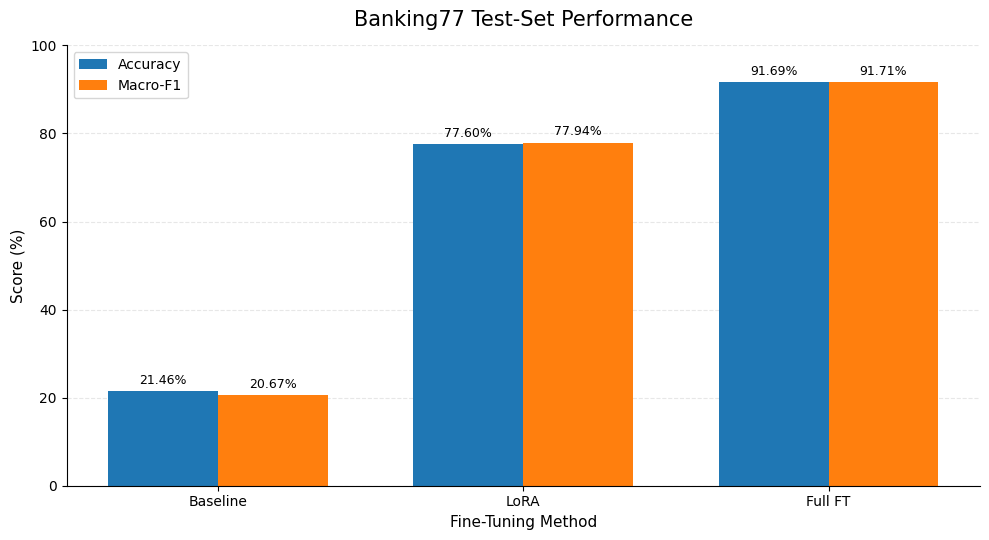

In [83]:

# Import Matplotlib for plotting and NumPy for bar positions
import matplotlib.pyplot as plt
import numpy as np

# Define the model names shown on the x-axis
models = ["Baseline", "LoRA", "Full FT"]

# Define accuracy values as percentages
accuracy = [21.46, 77.60, 91.69]

# Define Macro-F1 values as percentages
macro_f1 = [20.67, 77.94, 91.71]

# Create positions for the three groups of bars
x = np.arange(len(models))

# Set the width of each bar
width = 0.36

# Create the figure and axes
fig, ax = plt.subplots(figsize=(10, 5.5))

# Draw the accuracy bars
bars1 = ax.bar(
    x - width / 2,
    accuracy,
    width,
    label="Accuracy"
)

# Draw the Macro-F1 bars
bars2 = ax.bar(
    x + width / 2,
    macro_f1,
    width,
    label="Macro-F1"
)

# Add a title and axis labels
ax.set_title(
    "Banking77 Test-Set Performance",
    fontsize=15,
    pad=14
)
ax.set_xlabel("Fine-Tuning Method", fontsize=11)
ax.set_ylabel("Score (%)", fontsize=11)

# Set the model names as x-axis tick labels
ax.set_xticks(x)
ax.set_xticklabels(models)

# Keep the y-axis between 0% and 100%
ax.set_ylim(0, 100)

# Display percentage labels above each bar
ax.bar_label(
    bars1,
    labels=[f"{value:.2f}%" for value in accuracy],
    padding=3,
    fontsize=9
)

ax.bar_label(
    bars2,
    labels=[f"{value:.2f}%" for value in macro_f1],
    padding=3,
    fontsize=9
)

# Add a light horizontal grid for easier comparison
ax.yaxis.grid(True, linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

# Show the legend and remove unnecessary top/right borders
ax.legend(loc="upper left")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Adjust spacing and display the graph
plt.tight_layout()
plt.show()


In [84]:

# Save the figure at 300 DPI for use in the report
graph_path = RESULTS_DIR / "banking77_model_comparison.png"

fig.savefig(
    graph_path,
    dpi=300,
    bbox_inches="tight"
)

print("Graph saved to:", graph_path)


Graph saved to: /content/drive/MyDrive/7043SCN_Coursework/Task1_LLM_Finetuning/results/banking77_model_comparison.png
